<a href="https://colab.research.google.com/github/mateodaros/brujula-financiera/blob/main/TP_Te_Reemplaza_la_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ¿Te reemplaza la IA?
## Exposición del empleo argentino a la inteligencia artificial generativa

**Trabajo Práctico · Segundo Parcial · Economía Computacional**

---

### Resumen

La inteligencia artificial generativa (ChatGPT, Gemini, Claude) ya puede hacer parte de las tareas de muchos
trabajos: redactar, resumir, clasificar, cargar datos, responder consultas. La pregunta económica es **qué
trabajadores argentinos están más expuestos** y qué tienen en común.

Este trabajo cruza los **microdatos de la Encuesta Permanente de Hogares** (INDEC) con el **índice de exposición
ocupacional a la IA generativa de la OIT (2025)**, que puntúa 3.265 tareas de 427 ocupaciones. El resultado es una
medida de exposición para cada trabajador de la encuesta, que permite responder quiénes están más expuestos
según género, edad, educación, formalidad, región e ingreso.

> **Exposición no es pérdida de empleo.** Que una tarea pueda hacerla la IA no significa que el puesto
> desaparezca: en la mayoría de los casos el trabajo se transforma. La OIT lo mide como potencial técnico.

### Contenido

| Sección | Contenido |
|---|---|
| 1 | Parámetros |
| 2 | Importación de datos (EPH, índice OIT y tabla de correspondencia) |
| 3 | Validación de la base contra el INDEC |
| 4 | De las tareas a los grupos: la medida de exposición |
| 5 | Cruce de ocupaciones (EPH → OIT) |
| 6 | Resultados generales |
| 7 | ¿Quiénes están más expuestos? |
| 8 | Ingresos y masa salarial expuesta |
| 9 | Mapa por aglomerado |
| 10 | Regresión: ¿qué explica la exposición? |
| 11 | Controles de robustez |
| 12 | Clasificador de ocupaciones con IA |
| 13 | Informe automático |
| 14 | Agente con IA: preguntale a los datos |
| 15 | Metodología, supuestos y limitaciones |

### Fuentes

- **EPH, INDEC.** Base de microdatos individual. Si el sitio del INDEC no responde, se usa un espejo público en GitHub.
- **OIT.** Gmyrek, P., Berg, J. y otros (2025). *Generative AI and Jobs: A Refined Global Index of Occupational
  Exposure*. ILO Working Paper 140. Licencia CC BY 4.0. Este trabajo es una adaptación: no fue preparada ni
  revisada por la OIT.
- **Tabla de correspondencia CNO-2001 → CIUO-08.** Paquete `occupationcross` (Weksler, Lastra y Gutman), licencia MIT.

In [1]:
# ===============================================
# IMPORTACIÓN DE LIBRERÍAS
# ===============================================

import numpy as np                 # Cálculo numérico
import pandas as pd                # Tablas y estadísticas ponderadas
import matplotlib.pyplot as plt    # Gráficos
import io, os, sys, zipfile, tempfile, subprocess, urllib.request
import warnings
warnings.filterwarnings('ignore')

# pyreadr lee archivos .rda de R (la tabla de correspondencia viene en ese formato)
try:
    import pyreadr
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyreadr'], check=True)
    import pyreadr

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
print(f'NumPy {np.__version__} | Pandas {pd.__version__} | pyreadr listo')

NumPy 2.4.6 | Pandas 2.2.3 | pyreadr listo


## 1. Parámetros

Todo lo que se puede cambiar está en esta celda. El análisis principal usa el **4.° trimestre de 2025**, para que
todas las cifras del informe se puedan reproducir. Cambiando `PERIODO` se puede correr con otro trimestre, y la
sección 11 repite el cálculo con todos los trimestres disponibles.

In [2]:
# ===============================================
# PARÁMETROS
# ===============================================

# Trimestre de la EPH del análisis principal: (trimestre, año)
PERIODO = (4, 2025)

# Trimestres para el control de estabilidad en el tiempo (sección 11); los que no estén disponibles se omiten
PERIODOS_CONTROL = [(1, 2025), (2, 2025), (3, 2025), (4, 2025), (1, 2026), (2, 2026)]

# Fuentes
URL_INDEC   = 'https://www.indec.gob.ar/ftp/cuadros/menusuperior/eph/EPH_usu_{t}_Trim_{a}_txt.zip'
URL_ESPEJO  = ('https://raw.githubusercontent.com/matuteiglesias/microdatos-EPH-INDEC/master/'
               'microdatos-eph/raw/txt/individual/usu_individual_t{t}{aa}.txt')
URL_OIT     = ('https://raw.githubusercontent.com/pgmyrek/2025_GenAI_scores_ISCO08/main/'
               'Final_Scores_ISCO08_Gmyrek_et_al_2025.xlsx')
URL_CRUCE   = 'https://raw.githubusercontent.com/Guidowe/occupationcross/master/data/crosstable_cno2001_isco08.rda'
URL_AGLOS   = 'https://raw.githubusercontent.com/ropensci/eph/main/data/centroides_aglomerados.rda'

# Variables de la EPH que usamos (la base completa tiene 235 columnas)
COLUMNAS_EPH = ['CODUSU', 'NRO_HOGAR', 'COMPONENTE', 'ANO4', 'TRIMESTRE', 'REGION', 'AGLOMERADO',
                'PONDERA', 'CH04', 'CH06', 'NIVEL_ED', 'ESTADO', 'CAT_OCUP', 'PP04D_COD', 'PP07H',
                'P21', 'DECOCUR', 'PONDIIO', 'PP04A']

# Categorías de exposición de la OIT, de menor a mayor
CATEGORIAS = ['No expuesta', 'Mínima', 'Gradiente 1', 'Gradiente 2', 'Gradiente 3', 'Gradiente 4']
EXPUESTAS  = ['Gradiente 1', 'Gradiente 2', 'Gradiente 3', 'Gradiente 4']   # alguna exposición
ALTAS      = ['Gradiente 3', 'Gradiente 4']                                 # exposición alta

COLOR_CAT = {'No expuesta': '#C9D3CF', 'Mínima': '#9FB4AC', 'Gradiente 1': '#F2C46D',
             'Gradiente 2': '#E8954A', 'Gradiente 3': '#D1603D', 'Gradiente 4': '#8E2C2C'}

print(f'Período principal: {PERIODO[0]}T{PERIODO[1]}')
print('Períodos de control:', ', '.join(f'{t}T{a}' for t, a in PERIODOS_CONTROL))

Período principal: 4T2025
Períodos de control: 1T2025, 2T2025, 3T2025, 4T2025, 1T2026, 2T2026


## 2. Importación de datos

Se usan tres fuentes:

| Dato | Fuente | Para qué |
|---|---|---|
| Microdatos individuales de la EPH | INDEC (o espejo en GitHub) | Quién trabaja, en qué ocupación, cuánto gana |
| Puntaje de exposición de cada tarea | OIT, índice 2025 | Cuán expuesta está cada ocupación |
| Tabla de correspondencia de ocupaciones | Paquete `occupationcross` | Traducir el código argentino (CNO-2001) al internacional (CIUO-08) |

Las descargas están protegidas con `try/except`: si una fuente falla, el notebook lo informa y prueba la siguiente.

In [3]:
# ===============================================
# FUNCIÓN GENÉRICA DE DESCARGA
# ===============================================
# Algunos servidores rechazan los pedidos que se identifican como "Python-urllib".
# Por eso el pedido se presenta como un navegador.

HEADERS = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 '
                         '(KHTML, like Gecko) Chrome/124.0 Safari/537.36'}

def descargar(url, timeout=90):
    '''Devuelve (contenido en bytes, None) si salió bien, o (None, motivo) si falló.'''
    try:
        req = urllib.request.Request(url, headers=HEADERS)
        with urllib.request.urlopen(req, timeout=timeout) as r:
            return r.read(), None
    except Exception as e:
        return None, f'{type(e).__name__}: {e}'

print('Función de descarga lista')

Función de descarga lista


In [4]:
# ===============================================
# MICRODATOS DE LA EPH
# ===============================================

def leer_eph(contenido):
    '''Lee el archivo de texto de la EPH (separado por ;) quedándose con las columnas que usamos.'''
    df = pd.read_csv(io.BytesIO(contenido), sep=';', decimal=',', low_memory=False,
                     usecols=lambda c: c.upper() in COLUMNAS_EPH)
    df.columns = [c.upper() for c in df.columns]
    return df

def bajar_eph(t, a):
    '''Descarga la EPH individual de un trimestre: primero del INDEC y, si falla, del espejo en GitHub.
    Devuelve (base, fuente, errores).'''
    errores = []
    contenido, error = descargar(URL_INDEC.format(t=t, a=a))          # 1) sitio oficial, en .zip
    if contenido:
        try:
            with zipfile.ZipFile(io.BytesIO(contenido)) as z:
                nombre = [n for n in z.namelist() if 'individual' in n.lower() and n.lower().endswith('.txt')][0]
                return leer_eph(z.read(nombre)), f'INDEC, {t}.° trimestre {a}', errores
        except Exception as e:
            error = f'{type(e).__name__}: {e}'
    errores.append(f'INDEC -> {error}')
    contenido, error = descargar(URL_ESPEJO.format(t=t, aa=str(a)[2:]))   # 2) espejo público
    if contenido:
        return leer_eph(contenido), f'EPH del INDEC (espejo en GitHub), {t}.° trimestre {a}', errores
    errores.append(f'espejo -> {error}')
    return None, None, errores

eph, fuente_eph, errores = bajar_eph(*PERIODO)
if eph is None:
    raise RuntimeError('No se pudo descargar la EPH. Revisá la conexión:\n' + '\n'.join(errores))

TRIM, ANIO = int(eph['TRIMESTRE'].iloc[0]), int(eph['ANO4'].iloc[0])
for e in errores:
    print('   Aviso:', e[:110])
print(f'EPH -> {fuente_eph}')
print(f'   {len(eph):,} personas encuestadas | {eph.shape[1]} variables')

EPH -> INDEC, 4.° trimestre 2025
   43,703 personas encuestadas | 19 variables


In [5]:
# ===============================================
# ÍNDICE DE EXPOSICIÓN DE LA OIT (2025)
# ===============================================

contenido, error = descargar(URL_OIT)
if contenido is None:
    raise RuntimeError(f'No se pudo descargar el índice de la OIT: {error}')

oit = pd.read_excel(io.BytesIO(contenido),
                    usecols=['ISCO_08', 'Title', 'Task_ISCO', 'score_2023', 'score_2025',
                             'mean_score_2025', 'SD_2025', 'potential25'])

oit['isco4'] = oit['ISCO_08'].astype(int).astype(str).str.zfill(4)   # código de 4 dígitos
oit['isco2'] = oit['isco4'].str[:2]                                    # subgrupo (2 dígitos)
oit['isco1'] = oit['isco4'].str[:1]                                    # gran grupo (1 dígito)

print(f'Índice OIT -> {len(oit):,} tareas de {oit["isco4"].nunique()} ocupaciones')
print(f'   Puntaje de cada tarea: de 0 (la IA no puede hacerla) a 1 (podría hacerla entera)')
print(f'   Promedio de todas las tareas: {oit["score_2025"].mean():.3f}')

Índice OIT -> 3,265 tareas de 427 ocupaciones
   Puntaje de cada tarea: de 0 (la IA no puede hacerla) a 1 (podría hacerla entera)
   Promedio de todas las tareas: 0.294


In [6]:
# ===============================================
# TABLA DE CORRESPONDENCIA CNO-2001 -> CIUO-08
# ===============================================
# La EPH codifica la ocupación con el Clasificador Nacional de Ocupaciones (CNO-2001, 5 dígitos).
# La OIT usa la clasificación internacional CIUO-08 (ISCO-08). Esta tabla traduce una a la otra.

def leer_rda(url):
    '''Descarga un archivo .rda de R y devuelve su primera tabla como DataFrame.'''
    contenido, error = descargar(url)
    if contenido is None:
        raise RuntimeError(f'No se pudo descargar {url}: {error}')
    with tempfile.NamedTemporaryFile(suffix='.rda', delete=False) as f:
        f.write(contenido)
        ruta = f.name
    tabla = list(pyreadr.read_r(ruta).values())[0]
    os.remove(ruta)
    return tabla

cruce = leer_rda(URL_CRUCE).rename(columns={
    'cno.2001.code': 'cno', 'cno.2001.label': 'cno_desc',
    'isco08.2.digit.code': 'isco_cruce', 'isco08.2.digit.label': 'isco_desc'})

print(f'Tabla de correspondencia -> {len(cruce)} códigos CNO-2001')
print(cruce[['cno', 'isco_cruce', 'isco_desc']].head(4).to_string(index=False))

Tabla de correspondencia -> 594 códigos CNO-2001
  cno isco_cruce                                                                                                                           isco_desc
00001         11 Directores ejecutivos, personal directivo de la administración pública y miembros del poder ejecutivo y de los cuerpos legislativos
01001         11 Directores ejecutivos, personal directivo de la administración pública y miembros del poder ejecutivo y de los cuerpos legislativos
02001         26                                                                         Profesionales en derecho, en ciencias sociales y culturales
03001         13                                                                                   Directores y gerentes de producción y operaciones


## 3. Validación de la base

Antes de usar la EPH comprobamos que la estamos leyendo bien: con los ponderadores (`PONDERA`) tenemos que
reproducir las tasas oficiales que publica el INDEC para ese trimestre.

In [7]:
# ===============================================
# TASAS DEL MERCADO DE TRABAJO vs INDEC
# ===============================================

poblacion   = eph['PONDERA'].sum()
ocupados    = eph.loc[eph['ESTADO'] == 1, 'PONDERA'].sum()
desocupados = eph.loc[eph['ESTADO'] == 2, 'PONDERA'].sum()
activos     = ocupados + desocupados

tasas = {'Actividad':    activos / poblacion * 100,
         'Empleo':       ocupados / poblacion * 100,
         'Desocupación': desocupados / activos * 100}

# Tasas publicadas por el INDEC (informe técnico de mercado de trabajo, 31 aglomerados urbanos)
OFICIAL = {(4, 2025): {'Actividad': 48.6, 'Empleo': 45.0, 'Desocupación': 7.5},
           (1, 2026): {'Desocupación': 7.8},
           (2, 2026): {'Actividad': 48.9, 'Empleo': 45.0, 'Desocupación': 7.9}}

print(f'Población representada: {poblacion:,.0f} personas en 31 aglomerados urbanos')
print(f'Ocupados: {ocupados:,.0f}\n')
print(f'{"Tasa":<14}{"Calculada":>10}{"INDEC":>8}')
print('-' * 32)
oficial = OFICIAL.get((TRIM, ANIO), {})
for k, v in tasas.items():
    ref = f'{oficial[k]:.1f}' if k in oficial else 's/d'
    print(f'{k:<14}{v:>9.1f}%{ref:>8}')

if oficial:
    ok = all(abs(round(tasas[k], 1) - oficial[k]) < 0.15 for k in oficial)
    print(f'\nResultado: {"CORRECTO — la base reproduce las tasas oficiales" if ok else "REVISAR"}')
else:
    print(f'\nCompará con el informe técnico del INDEC del {TRIM}.° trimestre {ANIO}.')

Población representada: 30,032,745 personas en 31 aglomerados urbanos
Ocupados: 13,503,383

Tasa           Calculada   INDEC
--------------------------------
Actividad          48.6%    48.6
Empleo             45.0%    45.0
Desocupación        7.5%     7.5

Resultado: CORRECTO — la base reproduce las tasas oficiales


## 4. De las tareas a los grupos: la medida de exposición

La OIT descompone cada ocupación en tareas y le pone a cada tarea un puntaje de 0 a 1 según cuánto de ella podría
hacer la IA generativa. Con el **promedio (μ)** y el **desvío (σ)** de las tareas de una ocupación, la clasifica en
seis categorías:

| Categoría | Regla | Lectura |
|---|---|---|
| Gradiente 4 | μ ≥ 0,6 y μ − σ ≥ 0,5 | Exposición muy alta y pareja en todas las tareas |
| Gradiente 3 | 0,5 ≤ μ < 0,6 y μ + σ ≥ 0,5 | Exposición alta |
| Gradiente 2 | 0,4 ≤ μ < 0,5 y μ + σ ≥ 0,5 | Exposición moderada, con tareas muy distintas entre sí |
| Gradiente 1 | μ < 0,4 y μ + σ ≥ 0,5 | Exposición baja en promedio, pero con algunas tareas muy expuestas |
| Mínima | μ < 0,5 y μ + σ > 0,4 | Exposición limitada |
| No expuesta | el resto | La IA casi no toca sus tareas |

La tabla de correspondencia argentina llega hasta el **subgrupo de 2 dígitos** de la CIUO-08 (por ejemplo, 41 =
oficinistas). Por eso aplicamos la regla de la OIT a todas las tareas de cada subgrupo. En los pocos códigos en que
la tabla solo informa el gran grupo (1 dígito), usamos las tareas de ese gran grupo.

In [8]:
# ===============================================
# MEDIDA DE EXPOSICIÓN POR GRUPO OCUPACIONAL
# ===============================================

def gradiente_oit(mu, sd):
    '''Regla de la OIT (Working Paper 140, tabla 5) para clasificar según media y desvío de las tareas.'''
    if mu >= 0.6 and mu - sd >= 0.5:      return 'Gradiente 4'
    if 0.5 <= mu < 0.6 and mu + sd >= 0.5: return 'Gradiente 3'
    if 0.4 <= mu < 0.5 and mu + sd >= 0.5: return 'Gradiente 2'
    if mu < 0.4 and mu + sd >= 0.5:        return 'Gradiente 1'
    if mu < 0.5 and mu + sd > 0.4:         return 'Mínima'
    return 'No expuesta'

def resumir_grupos(nivel):
    '''Media y desvío de las tareas de cada grupo, y su categoría de exposición.'''
    g = oit.groupby(nivel).agg(mu=('score_2025', 'mean'), sd=('score_2025', 'std'),
                               tareas=('score_2025', 'size'), ocupaciones=('isco4', 'nunique'))
    g['categoria'] = [gradiente_oit(m, s) for m, s in zip(g['mu'], g['sd'])]
    return g

grupos = pd.concat([resumir_grupos('isco2'), resumir_grupos('isco1')])

# Nombres cortos en castellano de los subgrupos de la CIUO-08
NOMBRES = {
    '11': 'Directores y altos funcionarios', '12': 'Gerentes administrativos y comerciales',
    '13': 'Gerentes de producción', '14': 'Gerentes de comercios y servicios',
    '21': 'Profesionales de ciencias e ingeniería', '22': 'Profesionales de la salud',
    '23': 'Docentes', '24': 'Profesionales de negocios y administración',
    '25': 'Profesionales de informática', '26': 'Profesionales del derecho, sociales y culturales',
    '31': 'Técnicos de ciencias e ingeniería', '32': 'Técnicos de la salud',
    '33': 'Técnicos en finanzas y administración', '34': 'Técnicos jurídicos, sociales y culturales',
    '35': 'Técnicos en informática y comunicaciones', '41': 'Oficinistas',
    '42': 'Atención al público', '43': 'Empleados contables y de registro',
    '44': 'Otro personal administrativo', '51': 'Servicios personales', '52': 'Vendedores',
    '53': 'Cuidado de personas', '54': 'Seguridad', '61': 'Agricultores y ganaderos',
    '62': 'Trabajadores forestales y pesqueros', '63': 'Agricultura de subsistencia',
    '71': 'Oficiales de la construcción', '72': 'Metalurgia y mecánica', '73': 'Artesanos y gráficos',
    '74': 'Electricidad y electrónica', '75': 'Alimentos, madera y confección',
    '81': 'Operadores de máquinas fijas', '82': 'Ensambladores', '83': 'Conductores',
    '91': 'Limpieza y servicio doméstico', '92': 'Peones agropecuarios',
    '93': 'Peones de construcción e industria', '94': 'Ayudantes de cocina',
    '95': 'Vendedores ambulantes', '96': 'Recolectores y otras elementales',
    '1': 'Directores y gerentes (gran grupo)', '2': 'Profesionales (gran grupo)',
    '3': 'Técnicos (gran grupo)', '4': 'Administrativos (gran grupo)', '5': 'Servicios y ventas (gran grupo)',
    '6': 'Agropecuarios (gran grupo)', '7': 'Oficiales y operarios (gran grupo)',
    '8': 'Operadores de máquinas (gran grupo)', '9': 'Ocupaciones elementales (gran grupo)'}
grupos['nombre'] = grupos.index.map(NOMBRES)

tabla_grupos = grupos.loc[grupos.index.str.len() == 2].sort_values('mu', ascending=False)
print('SUBGRUPOS MÁS EXPUESTOS (promedio de sus tareas)\n')
print(tabla_grupos[['nombre', 'mu', 'sd', 'tareas', 'categoria']].head(8).round(3).to_string())
print('\nSUBGRUPOS MENOS EXPUESTOS\n')
print(tabla_grupos[['nombre', 'mu', 'sd', 'tareas', 'categoria']].tail(5).round(3).to_string())

SUBGRUPOS MÁS EXPUESTOS (promedio de sus tareas)

                                        nombre   mu   sd  tareas    categoria
41                                 Oficinistas 0.62 0.09      28  Gradiente 4
25                Profesionales de informática 0.54 0.08      56  Gradiente 3
43           Empleados contables y de registro 0.53 0.12      31  Gradiente 3
42                         Atención al público 0.52 0.12      70  Gradiente 3
44                Otro personal administrativo 0.51 0.16      34  Gradiente 3
24  Profesionales de negocios y administración 0.50 0.11      88  Gradiente 2
33       Técnicos en finanzas y administración 0.47 0.14     150  Gradiente 2
35    Técnicos en informática y comunicaciones 0.45 0.13      42  Gradiente 2

SUBGRUPOS MENOS EXPUESTOS

                                nombre   mu   sd  tareas    categoria
93  Peones de construcción e industria 0.14 0.07      53  No expuesta
71        Oficiales de la construcción 0.12 0.05      77  No expuesta
63        

## 5. Cruce de ocupaciones: de la EPH a la OIT

Cada ocupado de la EPH tiene un código CNO-2001 de 5 dígitos (`PP04D_COD`). Los dígitos tienen significado:

| Dígitos | Dimensión | Ejemplo |
|---|---|---|
| 1 y 2 | Carácter de la ocupación | 10 = gestión administrativa |
| 3 | Jerarquía | 3 = asalariado |
| 4 | Tecnología | 3 = opera sistemas informatizados |
| 5 | Calificación | 1 = profesional, 4 = no calificada |

El cruce se hace en tres pasos, de más preciso a menos:

1. **Exacto:** el código completo está en la tabla de correspondencia.
2. **Carácter + calificación:** si no está, se usa el subgrupo más frecuente entre los códigos con el mismo carácter y la misma calificación.
3. **Solo carácter:** último recurso.

In [9]:
# ===============================================
# CRUCE CON REGLAS DE RESPALDO
# ===============================================

# Grupo de destino: subgrupo de 2 dígitos, o gran grupo si la tabla solo informa 1 dígito (ej. '7(2)')
cruce['grupo'] = np.where(cruce['isco_cruce'].str.fullmatch(r'\d{2}'),
                          cruce['isco_cruce'],
                          cruce['isco_cruce'].str.extract(r'^(\d)')[0])
cruce['caracter']     = cruce['cno'].str[:2]
cruce['calificacion'] = cruce['cno'].str[4]

moda = lambda s: s.mode().iloc[0]
resp_car_cal = cruce.groupby(['caracter', 'calificacion'])['grupo'].agg(moda).rename('grupo_cc')
resp_car     = cruce.groupby('caracter')['grupo'].agg(moda).rename('grupo_c')

def asignar_exposicion(eph_df):
    '''A cada ocupado de una base EPH le asigna su grupo CIUO-08 y la exposición de ese grupo.'''
    oc = eph_df[eph_df['ESTADO'] == 1].copy()
    oc['cno'] = oc['PP04D_COD'].astype('Int64').astype(str).str.zfill(5)
    oc['caracter'] = oc['cno'].str[:2]
    oc['calificacion'] = oc['cno'].str[4]
    oc = (oc.merge(cruce[['cno', 'grupo']], on='cno', how='left')
            .merge(resp_car_cal.reset_index(), on=['caracter', 'calificacion'], how='left')
            .merge(resp_car.reset_index(), on='caracter', how='left'))
    oc['metodo'] = np.select(
        [oc['grupo'].notna(), oc['grupo_cc'].notna(), oc['grupo_c'].notna()],
        ['1. Exacto', '2. Carácter + calificación', '3. Solo carácter'], default='4. Sin código válido')
    oc['grupo'] = oc['grupo'].fillna(oc['grupo_cc']).fillna(oc['grupo_c'])
    # Le pegamos a cada trabajador la medida de exposición de su grupo
    oc = oc.merge(grupos[['mu', 'categoria', 'nombre']], left_on='grupo', right_index=True, how='left')
    oc.loc[oc['mu'].isna() & oc['grupo'].notna(), 'metodo'] = '5. Grupo sin puntaje OIT (FF.AA.)'
    oc['expuesto'] = oc['categoria'].isin(EXPUESTAS)
    oc['alta'] = oc['categoria'].isin(ALTAS)
    return oc

ocup = asignar_exposicion(eph)

cobertura = (ocup.groupby('metodo')['PONDERA'].sum() / ocup['PONDERA'].sum() * 100).round(1)
print('COBERTURA DEL CRUCE (% de los ocupados, ponderado)\n')
print(cobertura.to_string())

base = ocup[ocup['mu'].notna()].copy()       # ocupados con medida de exposición
print(f'\nOcupados con medida de exposición: {base["PONDERA"].sum():,.0f} '
      f'({base["PONDERA"].sum() / ocup["PONDERA"].sum():.1%} del total)')

COBERTURA DEL CRUCE (% de los ocupados, ponderado)

metodo
1. Exacto                           93.40
2. Carácter + calificación           5.90
3. Solo carácter                     0.00
4. Sin código válido                 0.30
5. Grupo sin puntaje OIT (FF.AA.)    0.40

Ocupados con medida de exposición: 13,405,130 (99.3% del total)


## 6. Resultados generales

¿Qué parte del empleo urbano argentino está en ocupaciones expuestas a la IA generativa? Todos los porcentajes
están **ponderados** con `PONDERA`: representan a la población, no a la muestra.

In [10]:
# ===============================================
# DISTRIBUCIÓN DEL EMPLEO POR CATEGORÍA DE EXPOSICIÓN
# ===============================================

W = base['PONDERA']
dist = (base.groupby('categoria')['PONDERA'].sum() / W.sum() * 100).reindex(CATEGORIAS).fillna(0)

pct_alguna = dist[EXPUESTAS].sum()
pct_alta   = dist[ALTAS].sum()
mu_medio   = np.average(base['mu'], weights=W)

print('EMPLEO URBANO POR CATEGORÍA DE EXPOSICIÓN (%)\n')
for cat, v in dist.items():
    print(f'   {cat:<13}{v:>6.1f}%  ' + '█' * int(round(v / 2)))

print(f'\nExposición media de las tareas (0 a 1):   {mu_medio:.3f}')
print(f'Ocupados con alguna exposición (G1 a G4): {pct_alguna:.1f}%  ≈ {pct_alguna/100*W.sum()/1e6:.1f} millones')
print(f'Ocupados con exposición alta (G3 y G4):   {pct_alta:.1f}%  ≈ {pct_alta/100*W.sum()/1e6:.1f} millones')

# Referencias de la OIT (Working Paper 140, 2025)
print('\nREFERENCIAS DE LA OIT')
print('   Mundo: 25% del empleo con alguna exposición; 3,3% en gradiente 4')
print('   Países de ingreso alto: 34% con alguna exposición; 17,3% en gradientes 3 y 4')
print('   Países de ingreso bajo: 11% con alguna exposición')

EMPLEO URBANO POR CATEGORÍA DE EXPOSICIÓN (%)

   No expuesta    53.7%  ███████████████████████████
   Mínima         10.8%  █████
   Gradiente 1    18.1%  █████████
   Gradiente 2     6.3%  ███
   Gradiente 3     4.5%  ██
   Gradiente 4     6.5%  ███

Exposición media de las tareas (0 a 1):   0.293
Ocupados con alguna exposición (G1 a G4): 35.5%  ≈ 4.8 millones
Ocupados con exposición alta (G3 y G4):   11.0%  ≈ 1.5 millones

REFERENCIAS DE LA OIT
   Mundo: 25% del empleo con alguna exposición; 3,3% en gradiente 4
   Países de ingreso alto: 34% con alguna exposición; 17,3% en gradientes 3 y 4
   Países de ingreso bajo: 11% con alguna exposición


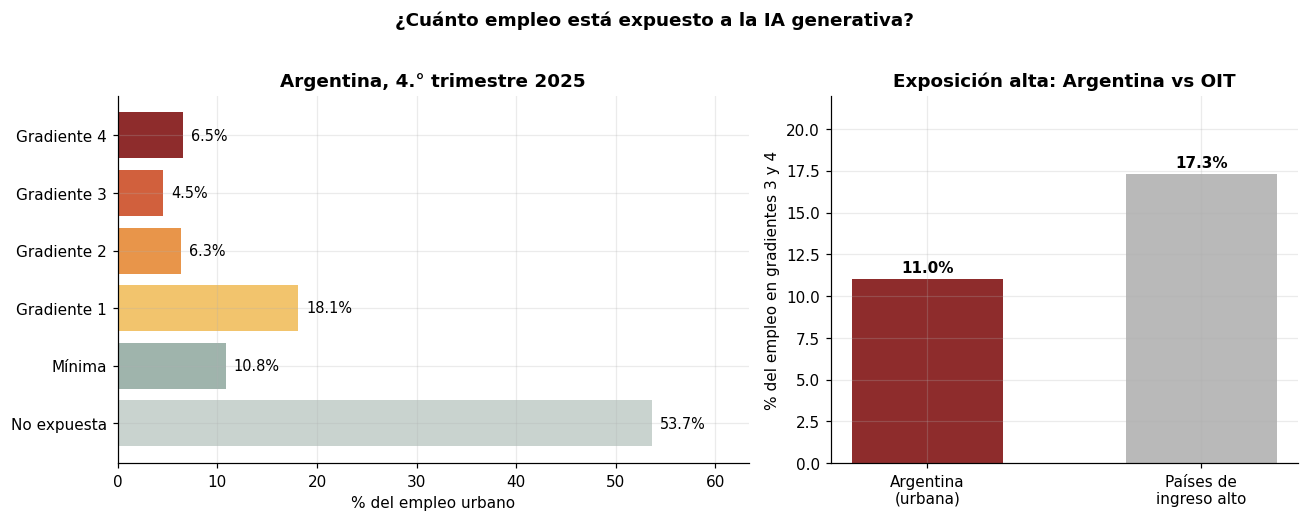

In [11]:
# ===============================================
# GRÁFICO 1 · DISTRIBUCIÓN DEL EMPLEO
# ===============================================

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.35, 1]})

# Panel izquierdo: el empleo en cada categoría
ax1.barh(CATEGORIAS, dist.values, color=[COLOR_CAT[c] for c in CATEGORIAS])
for i, v in enumerate(dist.values):
    ax1.text(v + 0.8, i, f'{v:.1f}%', va='center', fontsize=9.5)
ax1.set_xlim(0, dist.max() * 1.18)
ax1.set_xlabel('% del empleo urbano')
ax1.set_title(f'Argentina, {TRIM}.° trimestre {ANIO}', fontweight='bold')

# Panel derecho: exposición alta comparada con la OIT
comparacion = {'Argentina\n(urbana)': pct_alta, 'Países de\ningreso alto': 17.3}
barras = ax2.bar(comparacion.keys(), comparacion.values(), color=['#8E2C2C', '#B9B9B9'], width=0.55)
for b in barras:
    ax2.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.4, f'{b.get_height():.1f}%',
             ha='center', fontweight='bold')
ax2.set_ylabel('% del empleo en gradientes 3 y 4')
ax2.set_ylim(0, 22)
ax2.set_title('Exposición alta: Argentina vs OIT', fontweight='bold')

fig.suptitle('¿Cuánto empleo está expuesto a la IA generativa?', fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

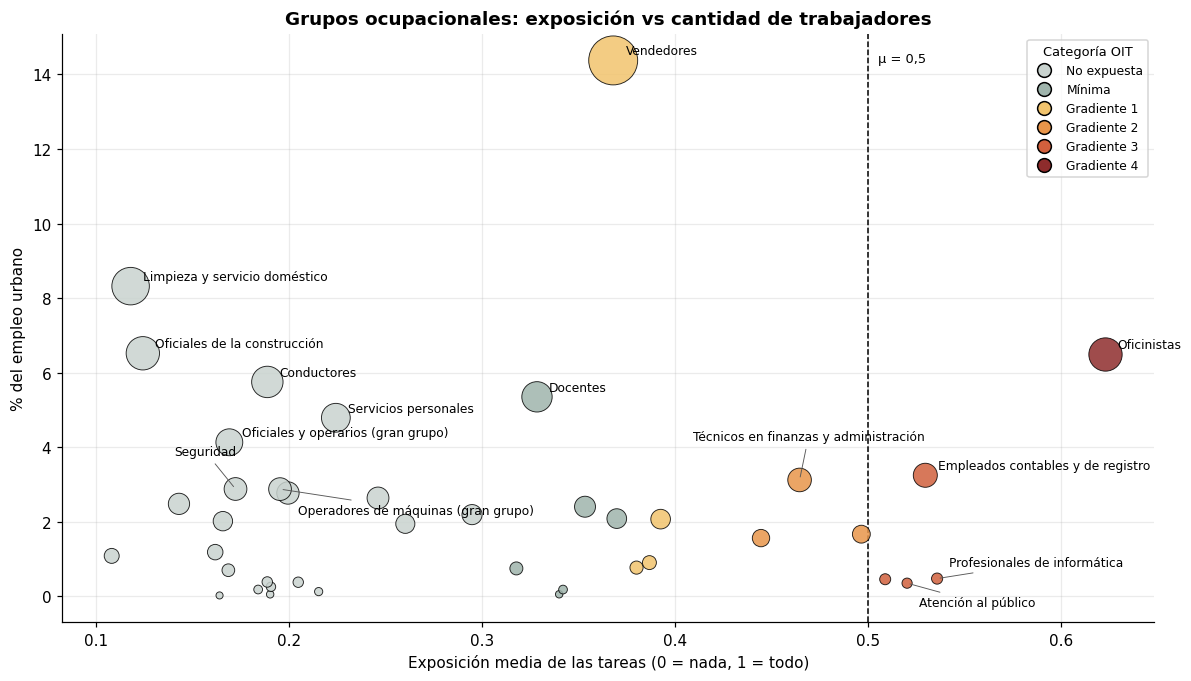

LOS 8 GRUPOS CON MÁS EMPLEO

                                   nombre  share   mu    categoria
grupo                                                             
52                             Vendedores  14.38 0.37  Gradiente 1
91          Limpieza y servicio doméstico   8.32 0.12  No expuesta
71           Oficiales de la construcción   6.52 0.12  No expuesta
41                            Oficinistas   6.51 0.62  Gradiente 4
83                            Conductores   5.75 0.19  No expuesta
23                               Docentes   5.35 0.33       Mínima
51                   Servicios personales   4.79 0.22  No expuesta
7      Oficiales y operarios (gran grupo)   4.13 0.17  No expuesta


In [12]:
# ===============================================
# GRÁFICO 2 · LOS GRUPOS OCUPACIONALES
# ===============================================
# Cada burbuja es un subgrupo: más a la derecha, más expuestas sus tareas; más arriba, más gente trabaja ahí.

por_grupo = (base.groupby('grupo').agg(ocupados=('PONDERA', 'sum'))
                 .join(grupos[['mu', 'categoria', 'nombre']]))
por_grupo['share'] = por_grupo['ocupados'] / por_grupo['ocupados'].sum() * 100

from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(11, 6.3))
for cat in CATEGORIAS:
    d = por_grupo[por_grupo['categoria'] == cat]
    ax.scatter(d['mu'], d['share'], s=d['share'] * 70 + 20, color=COLOR_CAT[cat],
               edgecolor='black', linewidth=0.6, alpha=0.85, label=cat, zorder=3)

# Etiquetas: los 12 grupos con más empleo y los 4 más expuestos (algunas corridas para que no se pisen)
destacados = set(por_grupo.nlargest(12, 'share').index) | set(por_grupo.nlargest(4, 'mu').index)
OFFSETS = {'54': (-40, 22), '8': (12, -16), '33': (-70, 26), '42': (8, -15), '25': (8, 8)}
for g in destacados:
    r = por_grupo.loc[g]
    flecha = dict(arrowstyle='-', lw=0.6, color='0.35') if g in OFFSETS else None
    ax.annotate(r['nombre'], (r['mu'], r['share']), textcoords='offset points',
                xytext=OFFSETS.get(g, (8, 4)), fontsize=8, arrowprops=flecha)

ax.axvline(0.5, color='black', ls='--', lw=1)
ax.text(0.505, ax.get_ylim()[1] * 0.95, 'μ = 0,5', fontsize=8.5)
ax.set_xlabel('Exposición media de las tareas (0 = nada, 1 = todo)')
ax.set_ylabel('% del empleo urbano')
ax.set_title('Grupos ocupacionales: exposición vs cantidad de trabajadores', fontweight='bold')
# Leyenda con círculos del mismo tamaño (el tamaño en el gráfico es la cantidad de ocupados)
marcas = [Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_CAT[c], markeredgecolor='black',
                 markersize=9, label=c) for c in CATEGORIAS]
ax.legend(handles=marcas, title='Categoría OIT', fontsize=8, title_fontsize=8.5, loc='upper right')
plt.tight_layout(); plt.show()

print('LOS 8 GRUPOS CON MÁS EMPLEO\n')
print(por_grupo.sort_values('share', ascending=False)[['nombre', 'share', 'mu', 'categoria']]
      .head(8).round(3).to_string())

## 7. ¿Quiénes están más expuestos?

Comparamos el porcentaje de ocupados en **exposición alta** (gradientes 3 y 4) entre grupos de trabajadores.
Usamos una sola función para todos los cortes, así cada tabla se arma igual.

In [13]:
# ===============================================
# VARIABLES DE CORTE
# ===============================================

base['Sexo'] = base['CH04'].map({1: 'Varones', 2: 'Mujeres'})

base['Edad'] = pd.cut(base['CH06'], bins=[0, 24, 34, 44, 54, 64, 120],
                      labels=['Hasta 24', '25 a 34', '35 a 44', '45 a 54', '55 a 64', '65 y más'])

base['Educación'] = base['NIVEL_ED'].map({1: 'Hasta primaria', 2: 'Hasta primaria', 7: 'Hasta primaria',
                                          3: 'Secundaria incompleta', 4: 'Secundaria completa',
                                          5: 'Superior incompleta', 6: 'Superior completa'})

base['Inserción'] = np.select(
    [(base['CAT_OCUP'] == 3) & (base['PP07H'] == 1), (base['CAT_OCUP'] == 3),
     base['CAT_OCUP'] == 2, base['CAT_OCUP'] == 1],
    ['Asalariado formal', 'Asalariado informal', 'Cuenta propia', 'Patrón'], default='Otro')

base['Región'] = base['REGION'].map({1: 'GBA', 40: 'Noroeste', 41: 'Noreste', 42: 'Cuyo',
                                     43: 'Pampeana', 44: 'Patagonia'})

def perfil(var):
    '''% en exposición alta, % con alguna exposición y exposición media, por categoría de var.'''
    def calc(d):
        w = d['PONDERA']
        return pd.Series({'Ocupados (miles)': w.sum() / 1e3,
                          '% exposición alta': np.average(d['alta'], weights=w) * 100,
                          '% alguna exposición': np.average(d['expuesto'], weights=w) * 100,
                          'Exposición media': np.average(d['mu'], weights=w)})
    return base.dropna(subset=[var]).groupby(var, observed=True).apply(calc)

ORDEN = {'Educación': ['Hasta primaria', 'Secundaria incompleta', 'Secundaria completa',
                       'Superior incompleta', 'Superior completa'],
         'Inserción': ['Asalariado formal', 'Asalariado informal', 'Cuenta propia', 'Patrón']}

perfiles = {}
for var in ['Sexo', 'Edad', 'Educación', 'Inserción', 'Región']:
    p = perfil(var)
    if var in ORDEN:
        p = p.reindex(ORDEN[var])
    perfiles[var] = p
    print(f'\n{var.upper()}')
    print(p.round(2).to_string())


SEXO
         Ocupados (miles)  % exposición alta  % alguna exposición  Exposición media
Sexo                                                                               
Mujeres          5,959.00              12.54                39.80              0.31
Varones          7,446.13               9.84                32.07              0.28

EDAD
          Ocupados (miles)  % exposición alta  % alguna exposición  Exposición media
Edad                                                                                
Hasta 24          1,387.01              11.77                41.26              0.29
25 a 34           3,040.56              10.28                36.12              0.29
35 a 44           3,531.74              11.76                36.34              0.30
45 a 54           2,986.04              11.55                34.50              0.30
55 a 64           1,778.10              11.37                29.48              0.28
65 y más            681.68               6.10            

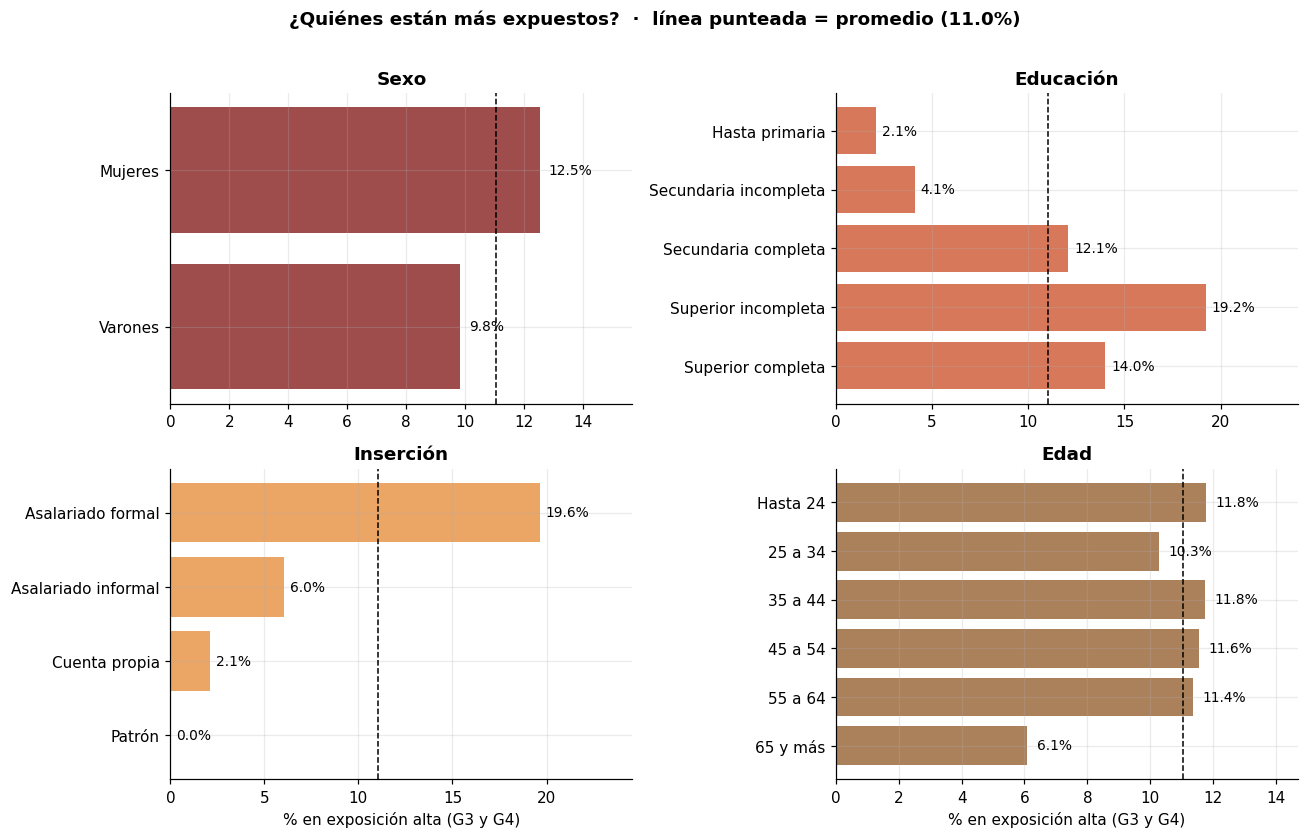

In [14]:
# ===============================================
# GRÁFICO 3 · PERFIL DE LOS MÁS EXPUESTOS
# ===============================================

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
paneles = [('Sexo', '#8E2C2C'), ('Educación', '#D1603D'), ('Inserción', '#E8954A'), ('Edad', '#9C6B3E')]
promedio = pct_alta

for ax, (var, color) in zip(axes.ravel(), paneles):
    p = perfiles[var]['% exposición alta']
    barras = ax.barh(p.index.astype(str), p.values, color=color, alpha=0.85)
    ax.invert_yaxis()
    ax.axvline(promedio, color='black', ls='--', lw=1)
    for b, v in zip(barras, p.values):
        ax.text(v + 0.3, b.get_y() + b.get_height() / 2, f'{v:.1f}%', va='center', fontsize=9)
    ax.set_xlim(0, max(p.max() * 1.25, promedio * 1.3))
    ax.set_title(var, fontweight='bold')

axes[1, 0].set_xlabel('% en exposición alta (G3 y G4)')
axes[1, 1].set_xlabel('% en exposición alta (G3 y G4)')
fig.suptitle(f'¿Quiénes están más expuestos?  ·  línea punteada = promedio ({promedio:.1f}%)',
             fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

## 8. Ingresos y masa salarial expuesta

¿La IA amenaza más a los trabajos que pagan poco o a los que pagan mucho? Usamos el **decil de ingreso de la
ocupación principal** (`DECOCUR`) que calcula el INDEC y el ingreso de la ocupación principal (`P21`). Para los
ingresos el INDEC indica usar el ponderador `PONDIIO`, que corrige por quienes no declaran ingresos.

In [15]:
# ===============================================
# EXPOSICIÓN POR DECIL DE INGRESO
# ===============================================

ing = base[(base['DECOCUR'].between(1, 10)) & (base['PONDIIO'] > 0) & (base['P21'] > 0)].copy()

por_decil = ing.groupby('DECOCUR').apply(lambda d: pd.Series({
    '% exposición alta':   np.average(d['alta'], weights=d['PONDIIO']) * 100,
    '% alguna exposición': np.average(d['expuesto'], weights=d['PONDIIO']) * 100,
    'Exposición media':    np.average(d['mu'], weights=d['PONDIIO']),
    'Ingreso medio ($)':   np.average(d['P21'], weights=d['PONDIIO'])}))

# Masa salarial: suma de los ingresos de la ocupación principal de todos los trabajadores
masa       = (ing['P21'] * ing['PONDIIO']).sum()
masa_alta  = (ing['P21'] * ing['PONDIIO'])[ing['alta']].sum()
empleo_alta = np.average(ing['alta'], weights=ing['PONDIIO']) * 100

print('EXPOSICIÓN POR DECIL DE INGRESO DE LA OCUPACIÓN PRINCIPAL\n')
print(por_decil.round(2).to_string())
print(f'\nTrabajadores en exposición alta: {empleo_alta:.1f}% del empleo con ingresos declarados')
print(f'Masa salarial de esos trabajadores: {masa_alta / masa * 100:.1f}% del total')
print(f'Ingreso medio, exposición alta vs resto: '
      f'${np.average(ing.loc[ing["alta"], "P21"], weights=ing.loc[ing["alta"], "PONDIIO"]):,.0f} vs '
      f'${np.average(ing.loc[~ing["alta"], "P21"], weights=ing.loc[~ing["alta"], "PONDIIO"]):,.0f}')

EXPOSICIÓN POR DECIL DE INGRESO DE LA OCUPACIÓN PRINCIPAL

         % exposición alta  % alguna exposición  Exposición media  Ingreso medio ($)
DECOCUR                                                                             
1                     3.62                25.59              0.23         138,813.49
2                     3.90                26.31              0.24         325,763.66
3                     7.02                27.91              0.26         468,593.88
4                    10.52                28.01              0.27         636,677.77
5                    10.42                30.26              0.28         778,276.39
6                    15.67                38.83              0.31         923,550.77
7                    14.48                39.34              0.31       1,047,899.61
8                    12.87                40.17              0.32       1,314,294.62
9                    16.21                43.01              0.34       1,695,052.45
10    

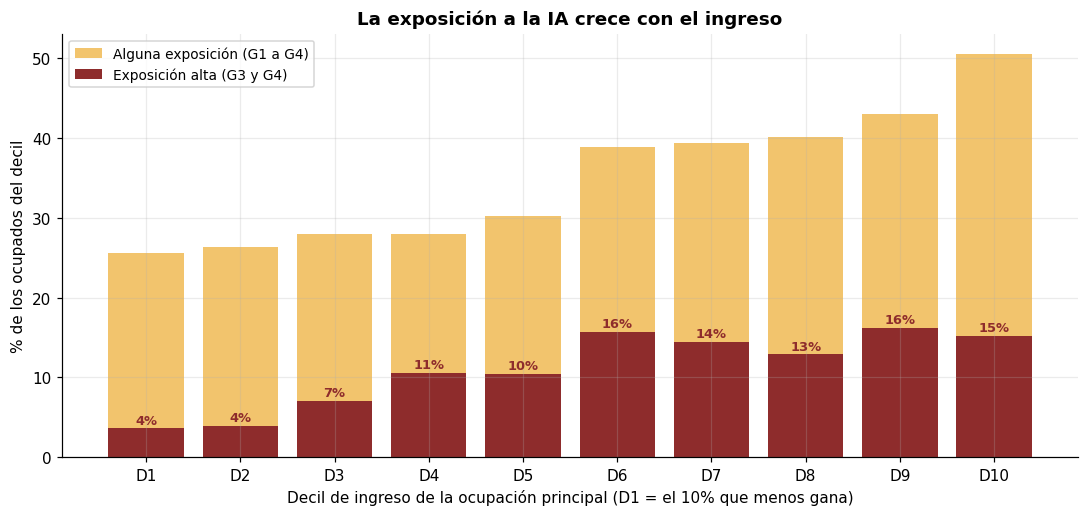

In [16]:
# ===============================================
# GRÁFICO 4 · EXPOSICIÓN E INGRESO
# ===============================================

fig, ax = plt.subplots(figsize=(10, 4.8))
x = por_decil.index.astype(int)
ax.bar(x, por_decil['% alguna exposición'], color='#F2C46D', label='Alguna exposición (G1 a G4)')
ax.bar(x, por_decil['% exposición alta'], color='#8E2C2C', label='Exposición alta (G3 y G4)')
for xi, v in zip(x, por_decil['% exposición alta']):
    ax.text(xi, v + 0.6, f'{v:.0f}%', ha='center', fontsize=8.5, color='#8E2C2C', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([f'D{i}' for i in x])
ax.set_xlabel('Decil de ingreso de la ocupación principal (D1 = el 10% que menos gana)')
ax.set_ylabel('% de los ocupados del decil')
ax.set_title('La exposición a la IA crece con el ingreso', fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

## 9. Mapa por aglomerado

La EPH cubre 31 aglomerados urbanos. Ubicamos cada uno con sus coordenadas (centroides publicados en el paquete
`eph` de rOpenSci): el tamaño del punto es la cantidad de ocupados y el color, el porcentaje en exposición alta.

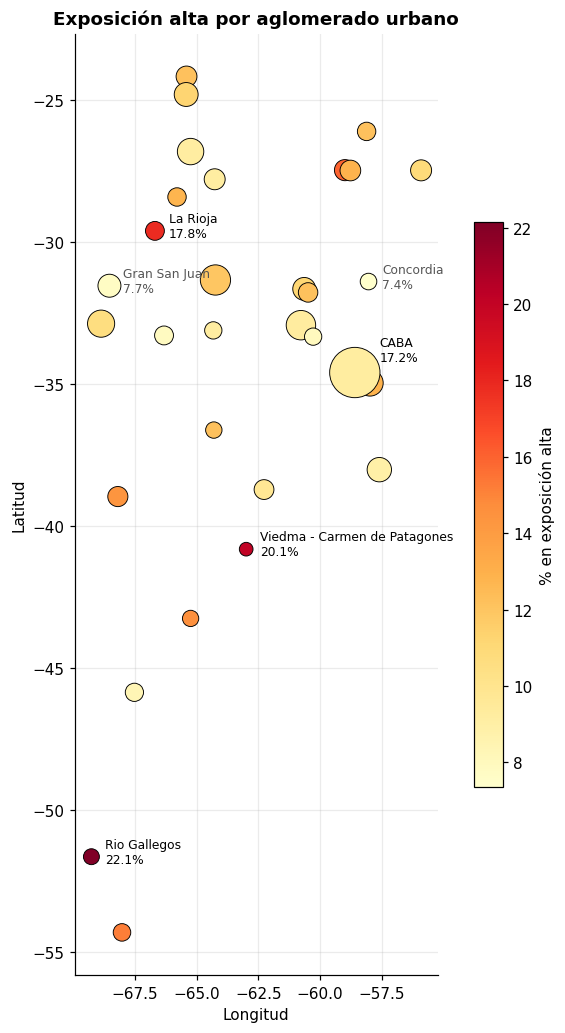

AGLOMERADOS MÁS Y MENOS EXPUESTOS (% en exposición alta)

           nombre_aglomerado  % exposición alta
                Rio Gallegos              22.10
Viedma - Carmen de Patagones              20.10
                    La Rioja              17.80
                        CABA              17.20
            Gran Resistencia              16.00
...
      nombre_aglomerado  % exposición alta
San Luis - El Chorrillo               7.80
          Gran San Juan               7.70
              Concordia               7.40

Correlación entre exposición alta y peso del empleo público en el aglomerado: 0.71
Los tres más expuestos tienen entre 39% y 45% de empleo público; el promedio urbano es 15%.


In [17]:
# ===============================================
# GRÁFICO 5 · MAPA DE AGLOMERADOS
# ===============================================

try:
    centroides = leer_rda(URL_AGLOS)
except Exception as e:
    centroides = None
    print(f'No se pudieron descargar los centroides ({e}); se omite el mapa.')

if centroides is not None:
    por_aglo = base.groupby('AGLOMERADO').apply(lambda d: pd.Series({
        'ocupados': d['PONDERA'].sum(),
        '% exposición alta': np.average(d['alta'], weights=d['PONDERA']) * 100,
        '% empleo público': np.average(d['PP04A'] == 1, weights=d['PONDERA']) * 100}))   # PP04A = 1: estatal
    por_aglo = por_aglo.join(centroides.set_index('AGLOMERADO')[['nombre_aglomerado', 'lon', 'lat']])

    fig, ax = plt.subplots(figsize=(7, 9.5))
    sc = ax.scatter(por_aglo['lon'], por_aglo['lat'], s=np.sqrt(por_aglo['ocupados']) / 2.2,
                    c=por_aglo['% exposición alta'], cmap='YlOrRd', edgecolor='black', linewidth=0.6, zorder=3)
    caba = por_aglo.loc[32]
    ax.annotate(f"CABA\n{caba['% exposición alta']:.1f}%", (caba['lon'], caba['lat']),
                textcoords='offset points', xytext=(14, 8), fontsize=8)
    for _, r in por_aglo.nlargest(3, '% exposición alta').iterrows():
        ax.annotate(f"{r['nombre_aglomerado']}\n{r['% exposición alta']:.1f}%", (r['lon'], r['lat']),
                    textcoords='offset points', xytext=(9, -4), fontsize=8)
    for _, r in por_aglo.nsmallest(2, '% exposición alta').iterrows():
        ax.annotate(f"{r['nombre_aglomerado']}\n{r['% exposición alta']:.1f}%", (r['lon'], r['lat']),
                    textcoords='offset points', xytext=(9, -4), fontsize=8, color='#555555')
    plt.colorbar(sc, ax=ax, shrink=0.6, label='% en exposición alta')
    ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')
    ax.set_aspect(1.15)
    ax.set_title('Exposición alta por aglomerado urbano', fontweight='bold')
    plt.tight_layout(); plt.show()

    print('AGLOMERADOS MÁS Y MENOS EXPUESTOS (% en exposición alta)\n')
    orden = por_aglo.sort_values('% exposición alta', ascending=False)
    print(orden[['nombre_aglomerado', '% exposición alta']].head(5).round(1).to_string(index=False))
    print('...')
    print(orden[['nombre_aglomerado', '% exposición alta']].tail(3).round(1).to_string(index=False))

    r = por_aglo['% exposición alta'].corr(por_aglo['% empleo público'])
    print(f'\nCorrelación entre exposición alta y peso del empleo público en el aglomerado: {r:.2f}')
    top3 = orden.head(3)['% empleo público']
    print(f'Los tres más expuestos tienen entre {top3.min():.0f}% y {top3.max():.0f}% de empleo público; '
          f'el promedio urbano es {np.average(base["PP04A"] == 1, weights=base["PONDERA"]) * 100:.0f}%.')

---
## 10. ¿Qué explica la exposición? Regresión

En la sección 7 vimos que las mujeres, los más educados y los asalariados formales están más expuestos. Pero esas
variables se mezclan: quizás las mujeres están más expuestas solo porque tienen más educación. Una **regresión
múltiple** permite medir el efecto de cada característica **manteniendo las demás constantes**.

| Modelo | Variable dependiente | Lectura del coeficiente |
|---|---|---|
| 1 | 100 si está en exposición alta, 0 si no (modelo lineal de probabilidad) | Puntos porcentuales de probabilidad |
| 2 | Exposición media de las tareas, de 0 a 100 | Puntos del índice |
| 3 | Igual que el 1, sumando el logaritmo del ingreso | Puntos porcentuales |

Se estima por **mínimos cuadrados ponderados** (`WLS`) con los ponderadores de la EPH y **errores estándar robustos**
(HC1), porque en un modelo lineal de probabilidad la varianza del error no es constante. Cada coeficiente se compara
contra una categoría de referencia: varón, 25 a 34 años, secundaria completa, asalariado formal y GBA.

In [18]:
# ===============================================
# REGRESIÓN: ¿QUÉ SE ASOCIA CON LA EXPOSICIÓN?
# ===============================================

import statsmodels.formula.api as smf

reg = base[base['Inserción'] != 'Otro'].dropna(subset=['Sexo', 'Edad', 'Educación', 'Región']).copy()
reg['alta100']   = reg['alta'].astype(int) * 100   # 100 si está en exposición alta
reg['mu100']     = reg['mu'] * 100                 # exposición media, de 0 a 100
reg['mujer']     = (reg['Sexo'] == 'Mujeres').astype(int)
reg['edad']      = reg['Edad'].astype(str)
reg['educ']      = reg['Educación']
reg['insercion'] = reg['Inserción']
reg['region']    = reg['Región']

FORMULA = ("mujer + C(edad, Treatment('25 a 34')) + C(educ, Treatment('Secundaria completa'))"
           " + C(insercion, Treatment('Asalariado formal')) + C(region, Treatment('GBA'))")

m1 = smf.wls('alta100 ~ ' + FORMULA, data=reg, weights=reg['PONDERA']).fit(cov_type='HC1')
m2 = smf.wls('mu100 ~ ' + FORMULA, data=reg, weights=reg['PONDERA']).fit(cov_type='HC1')

# Modelo 3: solo quienes declaran ingresos, con el ponderador de ingresos PONDIIO
r3 = reg[(reg['P21'] > 0) & (reg['PONDIIO'] > 0)].copy()
r3['log_ingreso'] = np.log(r3['P21'])
m3 = smf.wls('alta100 ~ ' + FORMULA + ' + log_ingreso', data=r3, weights=r3['PONDIIO']).fit(cov_type='HC1')

def etiqueta(p):
    '''Traduce el nombre técnico de cada coeficiente a una etiqueta legible.'''
    if p == 'Intercept':   return 'Constante'
    if p == 'mujer':       return 'Mujer'
    if p == 'log_ingreso': return 'Log(ingreso)'
    var, nivel = p.split('(')[1].split(',')[0], p.split('[T.')[1].rstrip(']')
    return {'edad': 'Edad', 'educ': 'Educación', 'insercion': 'Inserción', 'region': 'Región'}[var] + ': ' + nivel

def con_estrellas(m):
    '''Coeficiente con estrellas de significatividad: *** 1%, ** 5%, * 10%.'''
    est = lambda p: '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''
    return pd.Series({etiqueta(k): f'{v:+.2f}{est(m.pvalues[k])}' for k, v in m.params.items()})

tabla_reg = pd.concat({'(1) Exp. alta, pp': con_estrellas(m1),
                       '(2) Exp. media 0-100': con_estrellas(m2),
                       '(3) Exp. alta + ingreso': con_estrellas(m3)}, axis=1).fillna('')
tabla_reg.loc['Observaciones'] = [f'{int(m.nobs):,}' for m in (m1, m2, m3)]
tabla_reg.loc['R²'] = [f'{m.rsquared:.3f}' for m in (m1, m2, m3)]

print('RESULTADOS DE LA REGRESIÓN (MCP con errores robustos HC1)\n')
print(tabla_reg.to_string())
print('\n*** p<0,01  ** p<0,05  * p<0,1')

RESULTADOS DE LA REGRESIÓN (MCP con errores robustos HC1)

                                 (1) Exp. alta, pp (2) Exp. media 0-100 (3) Exp. alta + ingreso
Constante                                +17.28***            +29.75***                -16.28**
Edad: 35 a 44                                +1.01                -0.28                   +0.55
Edad: 45 a 54                                +1.60                -0.13                   +0.43
Edad: 55 a 64                             +4.20***                -0.05                +4.51***
Edad: 65 y más                             +2.95**              +1.68**                   +2.12
Edad: Hasta 24                             +2.89**             +2.23***                 +3.91**
Educación: Hasta primaria                 -7.50***             -5.98***                -6.90***
Educación: Secundaria incompleta          -5.88***             -4.44***                -6.01***
Educación: Superior completa                 -0.95             +7.00***      

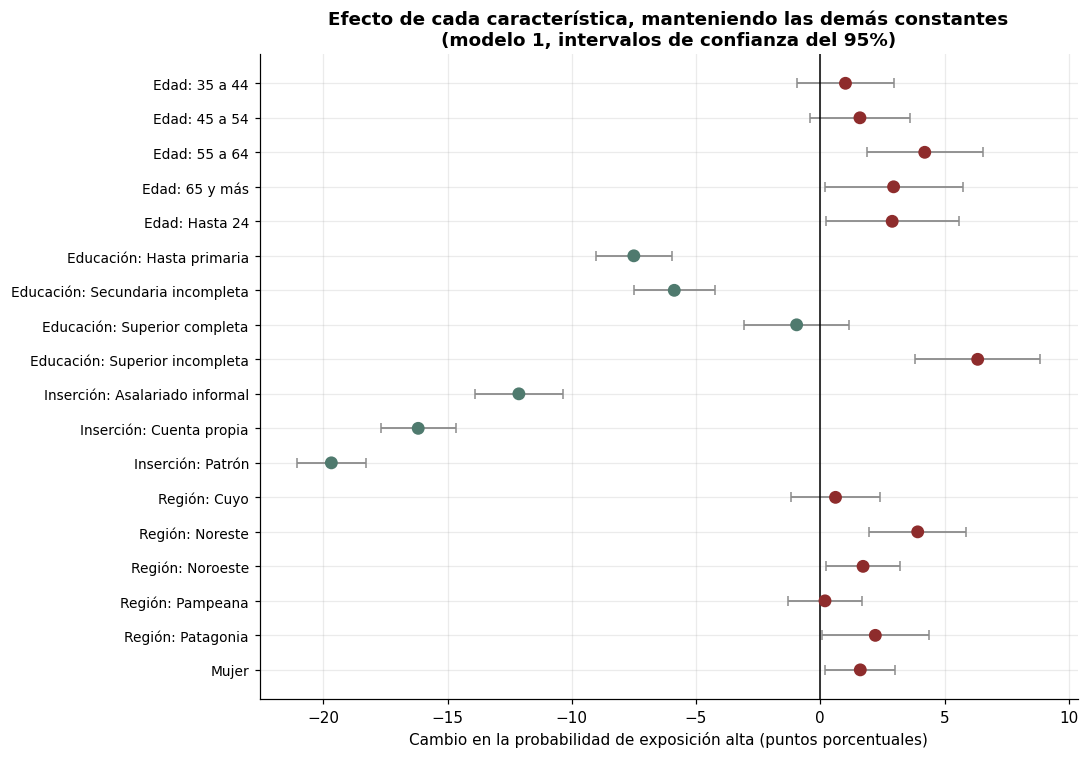

LECTURA
   Mujer: +1.6 pp frente a un varón con la misma edad, educación, inserción y región.
   Asalariado informal: -12.1 pp frente a un asalariado formal.
   Superior completa: -1.0 pp de exposición alta, pero +7.0 puntos de exposición media (modelo 2): los profesionales tienen tareas expuestas, aunque pocos llegan a G3 o G4.
   Ingreso (modelo 3): un ingreso 10% mayor suma +0.23 pp.


In [19]:
# ===============================================
# GRÁFICO 6 · EFECTO DE CADA CARACTERÍSTICA
# ===============================================

coef = pd.DataFrame({'coef': m1.params, 'li': m1.conf_int()[0], 'ls': m1.conf_int()[1]}).drop('Intercept')
coef.index = [etiqueta(i) for i in coef.index]
coef = coef.iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 7))
colores = ['#8E2C2C' if c > 0 else '#4F7A6E' for c in coef['coef']]
ax.errorbar(coef['coef'], range(len(coef)), xerr=[coef['coef'] - coef['li'], coef['ls'] - coef['coef']],
            fmt='none', ecolor='0.55', elinewidth=1.2, capsize=3, zorder=2)
ax.scatter(coef['coef'], range(len(coef)), c=colores, s=55, zorder=3)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(range(len(coef)))
ax.set_yticklabels(coef.index, fontsize=9)
ax.set_xlabel('Cambio en la probabilidad de exposición alta (puntos porcentuales)')
ax.set_title('Efecto de cada característica, manteniendo las demás constantes\n'
             '(modelo 1, intervalos de confianza del 95%)', fontweight='bold')
plt.tight_layout(); plt.show()

b = m1.params
print('LECTURA')
print(f'   Mujer: {b["mujer"]:+.1f} pp frente a un varón con la misma edad, educación, inserción y región.')
k_inf = "C(insercion, Treatment('Asalariado formal'))[T.Asalariado informal]"
print(f'   Asalariado informal: {b[k_inf]:+.1f} pp frente a un asalariado formal.')
k_sup = "C(educ, Treatment('Secundaria completa'))[T.Superior completa]"
print(f'   Superior completa: {b[k_sup]:+.1f} pp de exposición alta, pero {m2.params[k_sup]:+.1f} puntos de '
      f'exposición media (modelo 2): los profesionales tienen tareas expuestas, aunque pocos llegan a G3 o G4.')
print(f'   Ingreso (modelo 3): un ingreso 10% mayor suma {m3.params["log_ingreso"] * np.log(1.1):+.2f} pp.')

## 11. Controles de robustez

Un resultado es confiable si no depende de una decisión arbitraria del analista. Probamos cuatro cosas:

1. **Otro método de asignación.** En lugar de clasificar el subgrupo entero con la regla de la OIT, se le asigna a
   cada trabajador la proporción de ocupaciones de 4 dígitos de su subgrupo que la OIT ubica en cada categoría.
2. **Solo el cruce exacto.** Se descartan los trabajadores cuyo código se asignó con reglas de respaldo.
3. **Índice 2023 contra índice 2025.** La OIT publicó dos versiones del índice. En 2025 revisó a la baja tareas
   administrativas que en 2023 había sobreestimado y subió las ocupaciones digitales. Comparar muestra si la
   conclusión depende de la versión.
4. **Estabilidad en el tiempo.** Se repite el cálculo con otros trimestres de la EPH.

In [20]:
# ===============================================
# CONTROLES 1 Y 2 · MÉTODO ALTERNATIVO Y CRUCE EXACTO
# ===============================================

def resumen(d, w='PONDERA'):
    '''% en exposición alta, % con alguna exposición y exposición media de un grupo de ocupados.'''
    return pd.Series({'% exposición alta': np.average(d['alta'], weights=d[w]) * 100,
                      '% alguna exposición': np.average(d['expuesto'], weights=d[w]) * 100,
                      'Exposición media': np.average(d['mu'], weights=d[w])})

# Método alternativo: proporción de ocupaciones de 4 dígitos en cada categoría
TRADUCCION = {'Not Exposed': 'No expuesta', 'Minimal Exposure': 'Mínima',
              'Exposed: Gradient 1': 'Gradiente 1', 'Exposed: Gradient 2': 'Gradiente 2',
              'Exposed: Gradient 3': 'Gradiente 3', 'Exposed: Gradient 4': 'Gradiente 4'}
ocup4 = oit.drop_duplicates('isco4').copy()
ocup4['cat4'] = ocup4['potential25'].map(TRADUCCION)
prop = pd.concat([pd.crosstab(ocup4['isco2'], ocup4['cat4'], normalize='index'),
                  pd.crosstab(ocup4['isco1'], ocup4['cat4'], normalize='index')]).reindex(columns=CATEGORIAS,
                                                                                         fill_value=0)
alt = base[['grupo', 'PONDERA', 'mu']].join(prop, on='grupo')
alt['alta'] = alt[ALTAS].sum(axis=1)          # probabilidad de estar en una ocupación de G3 o G4
alt['expuesto'] = alt[EXPUESTAS].sum(axis=1)

robustez = pd.DataFrame({
    'Principal (regla OIT por subgrupo)': resumen(base),
    'Alternativo (ocupaciones de 4 dígitos)': resumen(alt),
    'Solo cruce exacto': resumen(base[base['metodo'] == '1. Exacto'])}).T

print('¿CAMBIA EL RESULTADO SEGÚN EL MÉTODO?\n')
print(robustez.round(2).to_string())

¿CAMBIA EL RESULTADO SEGÚN EL MÉTODO?

                                        % exposición alta  % alguna exposición  Exposición media
Principal (regla OIT por subgrupo)                  11.04                35.51              0.29
Alternativo (ocupaciones de 4 dígitos)              13.86                29.05              0.29
Solo cruce exacto                                   11.50                33.07              0.29


EXPOSICIÓN MEDIA DEL EMPLEO ARGENTINO
   Con el índice 2023: 0.309
   Con el índice 2025: 0.293
   En ocupaciones con μ ≥ 0,5: 10.6% (2023) vs 11.0% (2025)


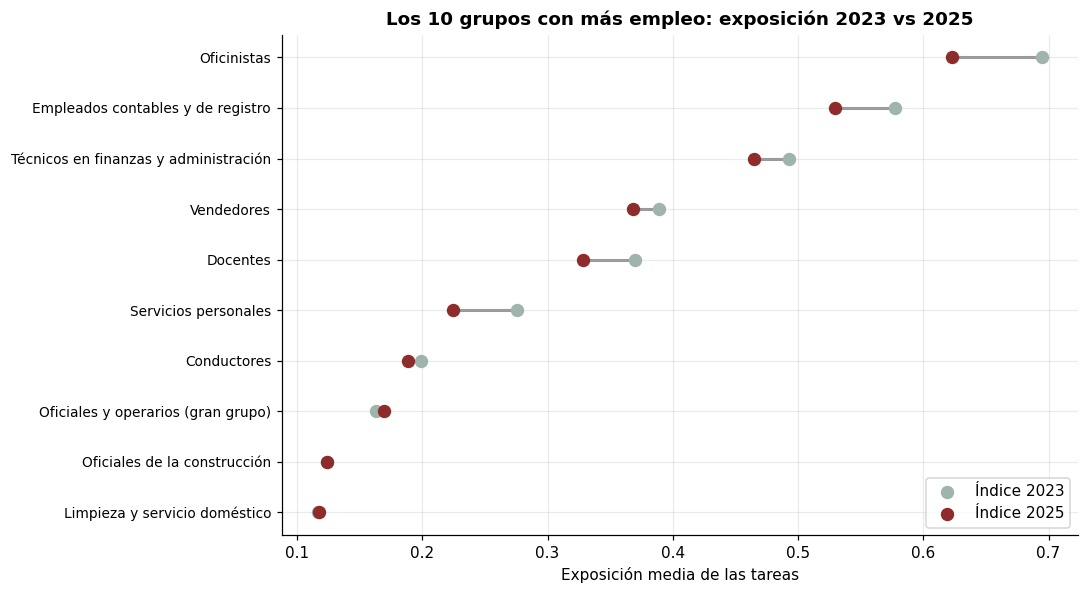


MAYORES SUBAS DE EXPOSICIÓN (2023 → 2025)
                                       nombre  mu23  mu25  delta
grupo                                                           
25               Profesionales de informática  0.40  0.54   0.13
94                        Ayudantes de cocina  0.11  0.16   0.06
11            Directores y altos funcionarios  0.29  0.34   0.04
21     Profesionales de ciencias e ingeniería  0.35  0.39   0.04
74                 Electricidad y electrónica  0.18  0.20   0.03


In [21]:
# ===============================================
# CONTROL 3 · ÍNDICE OIT 2023 vs 2025
# ===============================================
# Mismas tareas, puntuadas dos veces: en 2023 y en 2025. En 2025 la OIT corrigió a la baja varias tareas
# administrativas (con dos años de experiencia usando IA) y subió las ocupaciones digitales.

mu23 = pd.concat([oit.groupby('isco2')['score_2023'].mean(), oit.groupby('isco1')['score_2023'].mean()])
base['mu23'] = base['grupo'].map(mu23)

W = base['PONDERA']
print('EXPOSICIÓN MEDIA DEL EMPLEO ARGENTINO')
print(f'   Con el índice 2023: {np.average(base["mu23"], weights=W):.3f}')
print(f'   Con el índice 2025: {np.average(base["mu"], weights=W):.3f}')
print(f'   En ocupaciones con μ ≥ 0,5: {np.average(base["mu23"] >= 0.5, weights=W):.1%} (2023) '
      f'vs {np.average(base["mu"] >= 0.5, weights=W):.1%} (2025)')

cambio = (base.groupby('grupo').agg(ocupados=('PONDERA', 'sum'), mu23=('mu23', 'first'), mu25=('mu', 'first'))
              .join(grupos['nombre']))
cambio['delta'] = cambio['mu25'] - cambio['mu23']
top = cambio.nlargest(10, 'ocupados').sort_values('mu25')

fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (_, r) in enumerate(top.iterrows()):
    ax.plot([r['mu23'], r['mu25']], [i, i], color='0.6', lw=2, zorder=1)
ax.scatter(top['mu23'], range(len(top)), color='#9FB4AC', s=60, label='Índice 2023', zorder=2)
ax.scatter(top['mu25'], range(len(top)), color='#8E2C2C', s=60, label='Índice 2025', zorder=3)
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top['nombre'], fontsize=9)
ax.set_xlabel('Exposición media de las tareas')
ax.set_title('Los 10 grupos con más empleo: exposición 2023 vs 2025', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

print('\nMAYORES SUBAS DE EXPOSICIÓN (2023 → 2025)')
print(cambio[cambio.index.str.len() == 2].nlargest(5, 'delta')[['nombre', 'mu23', 'mu25', 'delta']]
      .round(3).to_string())

In [22]:
# ===============================================
# CONTROL 4 · ESTABILIDAD EN EL TIEMPO
# ===============================================
# Repetimos todo el cálculo con cada trimestre disponible. Si los resultados saltan mucho de un trimestre
# a otro, serían ruido de la muestra; si se mantienen, son una característica estable del empleo.

filas = {}
for t, a in PERIODOS_CONTROL:
    if (t, a) == PERIODO:
        e = eph
    else:
        e, _, _ = bajar_eph(t, a)
    if e is None:
        print(f'   {t}T{a}: no disponible, se omite')
        continue
    b_t = asignar_exposicion(e)
    b_t = b_t[b_t['mu'].notna()]
    filas[f'{t}T{a}'] = resumen(b_t)

estabilidad = pd.DataFrame(filas).T
print('\nRESULTADOS POR TRIMESTRE\n')
print(estabilidad.round(2).to_string())
rango = estabilidad['% exposición alta'].max() - estabilidad['% exposición alta'].min()
print(f'\nLa exposición alta se mueve en un rango de {rango:.1f} puntos entre trimestres.')


RESULTADOS POR TRIMESTRE

        % exposición alta  % alguna exposición  Exposición media
1T2025              11.64                36.30              0.30
2T2025              11.66                36.98              0.30
3T2025              11.77                37.32              0.30
4T2025              11.04                35.51              0.29
1T2026              11.53                35.60              0.29
2T2026              10.95                35.04              0.29

La exposición alta se mueve en un rango de 0.8 puntos entre trimestres.


## 12. Clasificador de ocupaciones con IA: «describí tu trabajo»

Para que cualquier persona pueda usar la herramienta, construimos un **clasificador de texto**: la persona describe
su trabajo con sus palabras y el modelo lo ubica en uno de los 40 subgrupos de la CIUO-08.

**Cómo funciona.** Cada subgrupo tiene una descripción con las ocupaciones y palabras típicas. El texto se convierte
en un vector con **TF-IDF** sobre fragmentos de 3 a 5 letras (así reconoce "programo" aunque la descripción diga
"programador") y se busca la descripción más parecida con la **similitud del coseno**. Es aprendizaje automático
clásico, con `scikit-learn`, y funciona sin conexión.

**Capa opcional con un modelo de lenguaje.** Si hay una clave de API, un LLM elige el subgrupo entre las opciones;
si no hay clave o falla, se usa el clasificador propio.

**Evaluación.** Se mide con 30 descripciones escritas a mano, distintas de las de la base de conocimiento, con su
respuesta correcta. Que las frases de prueba no estén copiadas en las descripciones es lo que hace honesta la medición.

In [23]:
# ===============================================
# BASE DE CONOCIMIENTO DEL CLASIFICADOR
# ===============================================
# Ocupaciones y palabras típicas de cada subgrupo de la CIUO-08, en castellano rioplatense.

DESCRIPCIONES = {
    '11': 'director ejecutivo gerente general CEO presidente de empresa legislador diputado senador concejal '
          'intendente ministro secretario de estado alto funcionario publico director de organismo',
    '12': 'gerente administrativo gerente comercial gerente de ventas gerente de recursos humanos gerente financiero '
          'gerente de marketing jefe de administracion director comercial gerente de finanzas',
    '13': 'gerente de produccion gerente de planta jefe de operaciones gerente de logistica gerente de compras '
          'director de obra gerente de sistemas gerente agropecuario jefe de fabrica',
    '14': 'gerente de hotel gerente de restaurante encargado de comercio dueño de negocio gerente de supermercado '
          'gerente de sucursal administrador de local encargado de tienda',
    '21': 'ingeniero ingeniera civil industrial electronico quimico fisico matematico biologo geologo arquitecto '
          'agrimensor estadistico investigador cientifico diseñador grafico diseñador industrial urbanista',
    '22': 'medico medica doctor clinico cirujano pediatra enfermero profesional licenciada en enfermeria odontologo '
          'dentista farmaceutico kinesiologo nutricionista veterinario obstetra fonoaudiologo',
    '23': 'docente maestro maestra profesor profesora enseñanza escuela colegio universidad jardin de infantes '
          'educacion especial capacitador preceptor',
    '24': 'contador contadora estudio contable auditor analista financiero asesor financiero administrador de empresas '
          'analista de recursos humanos marketing publicidad relaciones publicas consultor de negocios',
    '25': 'programador programadora desarrollador de software desarrollador web desarrollo de aplicaciones '
          'analista de sistemas ingeniero de software cientifico de datos base de datos ciberseguridad informatico',
    '26': 'abogado abogada juez escribano economista sociologo psicologo psicologa periodista redactor '
          'escritor traductor bibliotecario archivista artista musico actor sacerdote',
    '31': 'tecnico electronico tecnico quimico tecnico en construccion maestro mayor de obras dibujante tecnico '
          'tecnico mecanico inspector de calidad seguridad e higiene controlador aereo',
    '32': 'tecnico de laboratorio tecnico radiologo auxiliar de enfermeria enfermero enfermera tecnico '
          'en farmacia paramedico optico agente sanitario emergencias',
    '33': 'asistente contable corredor de seguros vendedor de seguros agente inmobiliario representante comercial '
          'despachante de aduana secretaria ejecutiva tasador analista de creditos agente de compras',
    '34': 'asistente social trabajador social fotografo decorador entrenador deportivo instructor de gimnasio '
          'personal trainer chef jefe de cocina tecnico de museo deportista',
    '35': 'tecnico en informatica soporte tecnico help desk tecnico de redes telecomunicaciones '
          'operador de radio y television tecnico de sonido webmaster',
    '41': 'oficinista empleado administrativo empleada administrativa secretaria secretario carga de datos '
          'data entry empleado de oficina dactilografo',
    '42': 'cajero de banco atencion al publico recepcionista telefonista call center operador de centro de '
          'llamadas agente de viajes turismo encuestador mostrador de informes cobrador',
    '43': 'empleado contable auxiliar contable liquidacion de sueldos empleado de deposito stock '
          'control de inventario despacho logistica empleado de banco',
    '44': 'empleado de archivo cartero correo codificador corrector empleado de personal tramites',
    '51': 'peluquero peluquera esteticista manicura cocinero cocinera mozo moza camarero restaurante bartender '
          'azafata guia de turismo conserje portero encargado de edificio cuidador de mascotas tatuador',
    '52': 'vendedor vendedora empleado de comercio cajera cajero supermercado repositor '
          'atencion en mostrador tienda promotor telemarketing kiosco kiosquero almacen playero estacion de servicio',
    '53': 'cuidadora de niños niñera cuidador de ancianos acompañante terapeutico auxiliar '
          'de geriatrico cuidado de personas mayores',
    '54': 'policia bombero guardia de seguridad vigilador vigilancia custodio agente penitenciario salvavidas '
          'seguridad privada',
    '61': 'agricultor productor agropecuario ganadero tambero horticultor jardinero avicultor apicultor viñatero',
    '62': 'pescador trabajador forestal hachero leñador acuicultor',
    '63': 'agricultura de subsistencia huerta familiar autoconsumo',
    '71': 'albañil constructor carpintero de obra plomero gasista pintor de obra techista yesero '
          'colocador de ceramicos vidriero',
    '72': 'soldador herrero tornero mecanico de autos chapista metalurgico matricero '
          'mecanico de motos mecanico de maquinaria',
    '73': 'joyero artesano imprenta trabajador grafico luthier ceramista alfarero tejedor artesanal',
    '74': 'electricista instalador electrico reparador de electrodomesticos tecnico en '
          'telefonia instalador de cable e internet',
    '75': 'panadero carnicero pastelero costurera modista sastre tapicero zapatero ebanista '
          'carpintero de muebles',
    '81': 'operario de fabrica operador de maquinas operario de planta maquina industrial envasado lavanderia '
          'industrial operador de planta quimica',
    '82': 'ensamblador armador operario de linea de montaje',
    '83': 'chofer camionero colectivero taxista remisero conductor de '
          'aplicacion repartidor en moto operador de grua maquinista ferroviario autoelevador',
    '91': 'empleada domestica servicio domestico limpieza personal de maestranza lavacoches lavandera',
    '92': 'peon rural peon de campo cosechero trabajador agricola temporario',
    '93': 'peon de albañil ayudante de construccion peon de fabrica cargador estibador empaquetador changarin',
    '94': 'ayudante de cocina lavaplatos preparador de comidas rapidas',
    '95': 'vendedor ambulante cuidacoches limpiavidrios lustrabotas mantero',
    '96': 'recolector de residuos barrendero cartonero reciclador repartidor de volantes mensajero cadete '
          'lector de medidores',
}

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vectorizador = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), strip_accents='unicode', lowercase=True)
codigos_clf = list(DESCRIPCIONES)
matriz_desc = vectorizador.fit_transform(DESCRIPCIONES.values())

print(f'Clasificador entrenado: {len(codigos_clf)} subgrupos | {matriz_desc.shape[1]:,} fragmentos de texto')

Clasificador entrenado: 40 subgrupos | 4,690 fragmentos de texto


In [24]:
# ===============================================
# CLASIFICAR UNA DESCRIPCIÓN Y DAR EL DIAGNÓSTICO
# ===============================================

def clasificar(texto, k=3):
    '''Devuelve los k subgrupos más parecidos a la descripción, con su similitud (0 a 1).'''
    sim = cosine_similarity(vectorizador.transform([texto]), matriz_desc)[0]
    orden = sim.argsort()[::-1][:k]
    return [(codigos_clf[i], sim[i]) for i in orden]

# Exposición de cada subgrupo y percentil dentro del empleo argentino
W = base['PONDERA']
def percentil(mu):
    '''% de los ocupados argentinos con una exposición menor a mu.'''
    return np.average(base['mu'] < mu, weights=W) * 100

def diagnostico(texto, n_tareas=3):
    '''Clasifica la descripción e imprime su exposición, con las tareas más y menos expuestas.'''
    opciones = clasificar(texto)
    g, s = opciones[0]
    r = grupos.loc[g]
    share = base.loc[base['grupo'] == g, 'PONDERA'].sum() / W.sum() * 100
    tareas = oit[oit['isco2'] == g].sort_values('score_2025', ascending=False)

    print(f'DESCRIPCIÓN: "{texto}"')
    print(f'Grupo más probable: {g} · {r["nombre"]} (similitud {s:.2f})')
    print('   Otras opciones: ' + ', '.join(f'{c} {grupos.loc[c, "nombre"]} ({v:.2f})' for c, v in opciones[1:]))
    print(f'Exposición media de sus tareas: {r["mu"]:.2f} -> {r["categoria"]}')
    print(f'Está más expuesto que el {percentil(r["mu"]):.0f}% de los ocupados argentinos')
    print(f'En este grupo trabaja el {share:.1f}% de los ocupados (≈ {share / 100 * W.sum():,.0f} personas)')
    print('Tareas más expuestas (texto original de la OIT):')
    for _, t in tareas.head(n_tareas).iterrows():
        print(f'   {t["score_2025"]:.2f} · {t["Task_ISCO"][:95]}')
    print('Tareas menos expuestas:')
    for _, t in tareas.tail(2).iterrows():
        print(f'   {t["score_2025"]:.2f} · {t["Task_ISCO"][:95]}')
    print()

for ejemplo in ['Trabajo en una oficina cargando facturas en el sistema',
                'Programo aplicaciones web en una empresa de software',
                'Soy maestra de primer grado']:
    diagnostico(ejemplo)

DESCRIPCIÓN: "Trabajo en una oficina cargando facturas en el sistema"
Grupo más probable: 41 · Oficinistas (similitud 0.24)
   Otras opciones: 34 Técnicos jurídicos, sociales y culturales (0.12), 92 Peones agropecuarios (0.10)
Exposición media de sus tareas: 0.62 -> Gradiente 4
Está más expuesto que el 93% de los ocupados argentinos
En este grupo trabaja el 6.5% de los ocupados (≈ 872,442 personas)
Tareas más expuestas (texto original de la OIT):
   0.76 · Screening requests for meetings or appointments and helping to organize meetings;
   0.74 · Entering numerical data, codes and text from source material into computer-compatible storage a
   0.72 · Receiving and registering invoices, forms, records and other documents for data capture;
Tareas menos expuestas:
   0.41 · Dealing with incoming or outgoing mail;
   0.39 · Sorting, opening and sending mail;

DESCRIPCIÓN: "Programo aplicaciones web en una empresa de software"
Grupo más probable: 25 · Profesionales de informática (similitud

In [25]:
# ===============================================
# EVALUACIÓN DEL CLASIFICADOR
# ===============================================
# 30 descripciones escritas a mano, con el o los subgrupos que se consideran correctos.

PRUEBA = [
    ('Trabajo en una oficina cargando facturas en el sistema', {'41', '43'}),
    ('Soy cajera en un supermercado', {'52'}),
    ('Programo aplicaciones web en una empresa de software', {'25'}),
    ('Doy clases de matemática en una escuela secundaria', {'23'}),
    ('Manejo un colectivo', {'83'}),
    ('Soy albañil, levanto paredes', {'71'}),
    ('Atiendo llamadas en un call center', {'42', '52'}),
    ('Limpio casas por hora', {'91'}),
    ('Soy contador en un estudio contable', {'24'}),
    ('Trabajo de mozo en un restaurante', {'51'}),
    ('Soy enfermera en un hospital', {'22', '32'}),
    ('Reparo autos en un taller mecánico', {'72'}),
    ('Vendo ropa en un local del shopping', {'52'}),
    ('Soy abogada y llevo juicios laborales', {'26'}),
    ('Trabajo como vigilador en un edificio', {'54'}),
    ('Cuido a una señora mayor', {'53'}),
    ('Hago el soporte técnico de las computadoras de la empresa', {'35'}),
    ('Soy médico clínico', {'22'}),
    ('Hago pan y facturas en una panadería', {'75'}),
    ('Soy peón en un campo', {'92'}),
    ('Liquido sueldos en el área de personal', {'43', '44', '41'}),
    ('Soy recepcionista en un hotel', {'42'}),
    ('Trabajo en una fábrica operando una máquina de envasado', {'81'}),
    ('Soy electricista, hago instalaciones en casas', {'74'}),
    ('Soy periodista en un diario', {'26'}),
    ('Manejo un camión de reparto', {'83'}),
    ('Soy ingeniero civil', {'21'}),
    ('Soy gerente de ventas de una empresa', {'12'}),
    ('Tengo un kiosco', {'52'}),
    ('Soy peluquera', {'51'}),
]

resultados = []
for texto, correctos in PRUEBA:
    top3 = [c for c, _ in clasificar(texto)]
    resultados.append({'Descripción': texto, 'Predicción': top3[0],
                       'Acierto top 1': top3[0] in correctos,
                       'Acierto top 3': bool(set(top3) & correctos)})
eval_clf = pd.DataFrame(resultados)

print('EVALUACIÓN DEL CLASIFICADOR (30 descripciones)\n')
print(f'   Acierta en el primer intento: {eval_clf["Acierto top 1"].mean():.0%}')
print(f'   La respuesta correcta está entre las 3 primeras: {eval_clf["Acierto top 3"].mean():.0%}')
errores = eval_clf[~eval_clf['Acierto top 1']]
if len(errores):
    print('\nDescripciones mal clasificadas en el primer intento:')
    for _, r in errores.iterrows():
        print(f'   "{r["Descripción"]}" -> {r["Predicción"]} {grupos.loc[r["Predicción"], "nombre"]}')

EVALUACIÓN DEL CLASIFICADOR (30 descripciones)

   Acierta en el primer intento: 90%
   La respuesta correcta está entre las 3 primeras: 100%

Descripciones mal clasificadas en el primer intento:
   "Soy albañil, levanto paredes" -> 93 Peones de construcción e industria
   "Limpio casas por hora" -> 95 Vendedores ambulantes
   "Vendo ropa en un local del shopping" -> 14 Gerentes de comercios y servicios


In [26]:
# ===============================================
# OPCIÓN: CLASIFICAR CON UN MODELO DE LENGUAJE
# ===============================================

def clasificar_con_llm(texto, api_key='', modelo='gpt-4o-mini'):
    '''Pide a un LLM que elija el subgrupo; si no hay clave o falla, usa el clasificador propio.'''
    api_key = api_key or os.environ.get('OPENAI_API_KEY', '')
    if not api_key:
        print('[Sin API key configurada -> se usa el clasificador propio]')
        return clasificar(texto)[0][0]
    opciones = '\n'.join(f'{c}: {grupos.loc[c, "nombre"]}' for c in codigos_clf)
    prompt = ('Clasificá la siguiente descripción de un trabajo en UNO de estos subgrupos de la CIUO-08. '
              'Respondé solo con el código de dos dígitos.\n\n'
              f'SUBGRUPOS:\n{opciones}\n\nDESCRIPCIÓN: {texto}')
    try:
        from openai import OpenAI
        resp = OpenAI(api_key=api_key).chat.completions.create(
            model=modelo, messages=[{'role': 'user', 'content': prompt}], max_tokens=5, temperature=0)
        codigo = resp.choices[0].message.content.strip()[:2]
        return codigo if codigo in DESCRIPCIONES else clasificar(texto)[0][0]
    except Exception as e:
        print(f'[Falló la llamada al LLM ({type(e).__name__}) -> se usa el clasificador propio]')
        return clasificar(texto)[0][0]

g = clasificar_con_llm('Atiendo llamadas en un call center')
print(f'Resultado: {g} · {grupos.loc[g, "nombre"]}')

[Sin API key configurada -> se usa el clasificador propio]
Resultado: 42 · Atención al público


## 13. Informe automático

La herramienta cierra traduciendo los números a un texto. Igual que en el clasificador, hay dos niveles: un
**generador propio por reglas**, que siempre funciona, y un **modelo de lenguaje opcional**. Los dos parten de una
**base factual**: la lista de cifras calculadas, para que el informe no invente números.

In [27]:
# ===============================================
# BASE FACTUAL
# ===============================================

edu, ins, sexo = perfiles['Educación'], perfiles['Inserción'], perfiles['Sexo']

def base_factual():
    '''Las cifras que el informe puede usar.'''
    return '\n'.join([
        f'Fuente: {fuente_eph}; índice OIT 2025.',
        f'Ocupados urbanos con medida de exposición: {W.sum():,.0f}.',
        f'Exposición alta (gradientes 3 y 4): {pct_alta:.1f}% (≈ {pct_alta / 100 * W.sum() / 1e6:.1f} millones).',
        f'Alguna exposición (gradientes 1 a 4): {pct_alguna:.1f}%.',
        f'Referencia OIT: 17,3% en gradientes 3 y 4 en países de ingreso alto.',
        f'Exposición alta por sexo: mujeres {sexo.loc["Mujeres", "% exposición alta"]:.1f}%, '
        f'varones {sexo.loc["Varones", "% exposición alta"]:.1f}%.',
        f'Exposición alta por inserción: formal {ins.loc["Asalariado formal", "% exposición alta"]:.1f}%, '
        f'informal {ins.loc["Asalariado informal", "% exposición alta"]:.1f}%, '
        f'cuenta propia {ins.loc["Cuenta propia", "% exposición alta"]:.1f}%.',
        f'Exposición alta por educación: hasta primaria {edu.loc["Hasta primaria", "% exposición alta"]:.1f}%, '
        f'superior completa {edu.loc["Superior completa", "% exposición alta"]:.1f}%.',
        f'Exposición alta por ingreso: decil 1 {por_decil.loc[1, "% exposición alta"]:.1f}%, '
        f'decil 10 {por_decil.loc[10, "% exposición alta"]:.1f}%.',
        f'Masa salarial de los trabajadores en exposición alta: {masa_alta / masa * 100:.1f}% del total.',
        f'Regresión: ser mujer {m1.params["mujer"]:+.1f} pp; asalariado informal {m1.params[k_inf]:+.1f} pp.',
        f'Grupo más expuesto con mucho empleo: Oficinistas (μ = {grupos.loc["41", "mu"]:.2f}).',
    ])

print(base_factual())

Fuente: INDEC, 4.° trimestre 2025; índice OIT 2025.
Ocupados urbanos con medida de exposición: 13,405,130.
Exposición alta (gradientes 3 y 4): 11.0% (≈ 1.5 millones).
Alguna exposición (gradientes 1 a 4): 35.5%.
Referencia OIT: 17,3% en gradientes 3 y 4 en países de ingreso alto.
Exposición alta por sexo: mujeres 12.5%, varones 9.8%.
Exposición alta por inserción: formal 19.6%, informal 6.0%, cuenta propia 2.1%.
Exposición alta por educación: hasta primaria 2.1%, superior completa 14.0%.
Exposición alta por ingreso: decil 1 3.6%, decil 10 15.2%.
Masa salarial de los trabajadores en exposición alta: 13.5% del total.
Regresión: ser mujer +1.6 pp; asalariado informal -12.1 pp.
Grupo más expuesto con mucho empleo: Oficinistas (μ = 0.62).


In [28]:
# ===============================================
# GENERADOR DE INFORME (lógica propia, sin API)
# ===============================================

def redactar_informe():
    '''Redacta el informe ejecutivo a partir de las cifras calculadas.'''
    m_sexo = sexo.loc['Mujeres', '% exposición alta'] - sexo.loc['Varones', '% exposición alta']
    brecha_formal = ins.loc['Asalariado formal', '% exposición alta'] / ins.loc['Asalariado informal', '% exposición alta']
    d1, d10 = por_decil.loc[1, '% exposición alta'], por_decil.loc[10, '% exposición alta']
    partes = [
        f'INFORME EJECUTIVO — ¿Te reemplaza la IA? ({fuente_eph})',

        (f'El {pct_alta:.1f}% de los ocupados urbanos, unos {pct_alta / 100 * W.sum() / 1e6:.1f} millones de '
         f'personas, trabaja en ocupaciones de exposición alta a la inteligencia artificial generativa '
         f'(gradientes 3 y 4 de la OIT). En los países de ingreso alto esa proporción es de 17,3%. '
         f'Si se suman las ocupaciones con exposición moderada, el {pct_alguna:.1f}% del empleo tiene alguna exposición.'),

        (f'La exposición no es pareja. Las mujeres están {abs(m_sexo):.1f} puntos más expuestas que los varones, '
         f'porque se concentran en tareas administrativas y de atención al público. Los asalariados formales '
         f'están {brecha_formal:.1f} veces más expuestos que los informales, y la exposición sube con el ingreso: '
         f'{d1:.1f}% en el decil más bajo contra {d10:.1f}% en el más alto.'),

        (f'La regresión confirma que estas diferencias se mantienen al comparar trabajadores parecidos: '
         f'ser mujer suma {m1.params["mujer"]:+.1f} puntos porcentuales de probabilidad de exposición alta y ser '
         f'asalariado informal {m1.params[k_inf]:+.1f}, manteniendo constantes la edad, la educación y la región.'),

        (f'A diferencia de las olas anteriores de automatización, que afectaron sobre todo a trabajos manuales y '
         f'rutinarios, la IA generativa expone al empleo de oficina, formal y de ingresos medios y altos. '
         f'Los trabajadores en exposición alta concentran el {masa_alta / masa * 100:.1f}% de la masa salarial.'),

        ('Exposición no significa pérdida del empleo: la OIT mide el potencial técnico de que la IA realice las tareas. '
         'En la mayoría de las ocupaciones el impacto más probable es la transformación del trabajo, lo que pone el foco '
         'en la capacitación de los trabajadores administrativos y de atención al público.'),
    ]
    return '\n\n'.join(partes)

informe = redactar_informe()
print(informe)

INFORME EJECUTIVO — ¿Te reemplaza la IA? (INDEC, 4.° trimestre 2025)

El 11.0% de los ocupados urbanos, unos 1.5 millones de personas, trabaja en ocupaciones de exposición alta a la inteligencia artificial generativa (gradientes 3 y 4 de la OIT). En los países de ingreso alto esa proporción es de 17,3%. Si se suman las ocupaciones con exposición moderada, el 35.5% del empleo tiene alguna exposición.

La exposición no es pareja. Las mujeres están 2.7 puntos más expuestas que los varones, porque se concentran en tareas administrativas y de atención al público. Los asalariados formales están 3.3 veces más expuestos que los informales, y la exposición sube con el ingreso: 3.6% en el decil más bajo contra 15.2% en el más alto.

La regresión confirma que estas diferencias se mantienen al comparar trabajadores parecidos: ser mujer suma +1.6 puntos porcentuales de probabilidad de exposición alta y ser asalariado informal -12.1, manteniendo constantes la edad, la educación y la región.

A difer

In [29]:
# ===============================================
# OPCIÓN: REDACCIÓN CON UN MODELO DE LENGUAJE
# ===============================================

def redactar_con_llm(api_key='', modelo='gpt-4o-mini'):
    '''Redacta el informe con un LLM a partir de la base factual; si falla, usa el generador propio.'''
    api_key = api_key or os.environ.get('OPENAI_API_KEY', '')
    if not api_key:
        print('[Sin API key configurada -> se usa el generador propio]')
        return redactar_informe()
    prompt = ('Sos un economista laboral. Con estos resultados sobre la exposición del empleo argentino a la IA '
              'generativa, redactá un resumen ejecutivo de no más de 200 palabras para un público general. '
              'No inventes ningún número que no esté en los datos.\n\nDATOS:\n' + base_factual())
    try:
        from openai import OpenAI
        resp = OpenAI(api_key=api_key).chat.completions.create(
            model=modelo, messages=[{'role': 'user', 'content': prompt}], max_tokens=400, temperature=0.4)
        return resp.choices[0].message.content
    except Exception as e:
        print(f'[Falló la llamada al LLM ({type(e).__name__}) -> se usa el generador propio]')
        return redactar_informe()

print(redactar_con_llm()[:300] + '...')

[Sin API key configurada -> se usa el generador propio]
INFORME EJECUTIVO — ¿Te reemplaza la IA? (INDEC, 4.° trimestre 2025)

El 11.0% de los ocupados urbanos, unos 1.5 millones de personas, trabaja en ocupaciones de exposición alta a la inteligencia artificial generativa (gradientes 3 y 4 de la OIT). En los países de ingreso alto esa proporción es de 17...


## 14. Agente con IA: preguntale a los datos

El clasificador responde una sola pregunta: *¿qué tan expuesto está mi trabajo?* El **agente** responde preguntas libres
sobre los resultados, como *«¿cuántas mujeres de Córdoba están en exposición alta?»* o *«comparando personas parecidas,
¿los informales están más o menos expuestos?»*.

Un agente es un modelo de lenguaje que, en lugar de contestar de memoria, **decide qué herramienta usar, la ejecuta y
redacta la respuesta con el resultado**. Acá las herramientas son funciones de Python que calculan con la EPH ya procesada:

> pregunta → **Gemini** elige la herramienta y sus argumentos → **Python** calcula con la EPH → **Gemini** redacta la respuesta con esas cifras

Así, los números siempre salen de los datos y no de lo que el modelo "recuerda". Cada llamada se imprime, para poder
auditar qué hizo el agente.

**Para usar Gemini** hace falta una clave de Google AI Studio (aistudio.google.com → *Get API key*), que tiene un nivel
gratuito. En Colab se guarda en **Secretos** (ícono de la llave, a la izquierda) con el nombre `GEMINI_API_KEY`, activando
el acceso para este notebook. **Sin clave**, el agente funciona igual en **modo local**: un enrutador por reglas elige la
herramienta y arma la respuesta con plantillas.

In [30]:
# ===============================================
# CONFIGURACIÓN DEL AGENTE
# ===============================================

import json, re, textwrap, unicodedata

def leer_clave():
    '''Busca la clave de Gemini en los Secretos de Colab o en una variable de entorno.'''
    try:
        from google.colab import userdata
        return userdata.get('GEMINI_API_KEY') or ''
    except Exception:
        return os.environ.get('GEMINI_API_KEY', '') or os.environ.get('GOOGLE_API_KEY', '')

# Modelos a probar, en orden: si uno no está disponible para la clave, se pasa al siguiente
MODELOS_GEMINI = ['gemini-3.8-flash', 'gemini-3.5-flash-lite', 'gemini-2.5-flash']

cliente = None
clave = leer_clave()
if clave:
    try:
        from google import genai
        from google.genai import types
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'google-genai'], check=True)
        from google import genai
        from google.genai import types
    cliente = genai.Client(api_key=clave)
    print('Agente en modo Gemini: el modelo elige las herramientas y redacta las respuestas.')
else:
    print('Agente en modo local (sin clave de Gemini): un enrutador por reglas elige las herramientas.')
    print('Para usar Gemini, cargá la clave como GEMINI_API_KEY en los Secretos de Colab (ícono de la llave),')
    print('activá «Acceso al notebook» y volvé a correr esta celda.')

Agente en modo Gemini: el modelo elige las herramientas y redacta las respuestas.


In [31]:
# ===============================================
# HERRAMIENTAS DEL AGENTE
# ===============================================
# Cada herramienta es una función de Python que calcula con la EPH y devuelve un diccionario.
# El modelo solo elige qué herramienta usar y con qué argumentos: los números los calcula Python.

def normalizar(t):
    '''Minúsculas y sin tildes, para comparar textos.'''
    t = unicodedata.normalize('NFKD', str(t).lower())
    return ''.join(c for c in t if not unicodedata.combining(c)).strip()

def buscar_opcion(valor, opciones):
    '''Busca un valor entre las opciones válidas sin importar tildes ni mayúsculas ("córdoba" encuentra "Gran Córdoba").'''
    palabras = normalizar(valor).split()
    candidatas = [o for o in opciones
                  if all(any(p.startswith(x) for p in normalizar(o).split()) for x in palabras)]
    exactas = [o for o in candidatas if normalizar(o) == normalizar(valor)]
    return exactas[0] if exactas else (candidatas[0] if len(candidatas) == 1 else None)

miles = lambda x: f'{x:,.0f}'.replace(',', '.')

def limpiar(r):
    '''Pasa el resultado a tipos de Python comunes (sin tipos de NumPy), para poder mandárselo al modelo.'''
    return json.loads(json.dumps(r, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))

# Nombres de los aglomerados (los centroides de la sección 9 vienen sin tildes)
ACENTOS = {'Rio Gallegos': 'Río Gallegos', 'Ushuaia - Rio Grande': 'Ushuaia - Río Grande', 'Rio Cuarto': 'Río Cuarto',
           'Bahia Blanca - Cerri': 'Bahía Blanca - Cerri', 'Gran Tucumán - Tafi Viejo': 'Gran Tucumán - Tafí Viejo',
           'San Nicolas - Villa Constitiución': 'San Nicolás - Villa Constitución'}
NOMBRES_AGLO = ({k: ACENTOS.get(v, v) for k, v in centroides.set_index('AGLOMERADO')['nombre_aglomerado'].items()}
                if centroides is not None else {})
base['Aglomerado'] = base['AGLOMERADO'].map(NOMBRES_AGLO)
ing['Aglomerado'] = ing['AGLOMERADO'].map(NOMBRES_AGLO)

COLUMNA = {'sexo': 'Sexo', 'edad': 'Edad', 'educacion': 'Educación', 'insercion': 'Inserción',
           'region': 'Región', 'aglomerado': 'Aglomerado'}
OPCIONES = {'sexo': ['Mujeres', 'Varones'],
            'edad': list(base['Edad'].cat.categories),
            'educacion': ORDEN['Educación'],
            'insercion': ORDEN['Inserción'],
            'region': ['GBA', 'Noroeste', 'Noreste', 'Cuyo', 'Pampeana', 'Patagonia'],
            'aglomerado': sorted(base['Aglomerado'].dropna().unique())}


# --- Herramienta 1: exposición de un grupo de personas --------------------------------
def exposicion_de_personas(sexo=None, edad=None, educacion=None, insercion=None, region=None,
                           aglomerado=None, decil=None):
    '''Exposición de los ocupados que cumplen los filtros indicados (los que quedan en None no filtran).'''
    filtros = {k: v for k, v in dict(sexo=sexo, edad=edad, educacion=educacion, insercion=insercion,
                                      region=region, aglomerado=aglomerado).items() if v}
    d, peso = (ing, 'PONDIIO') if decil else (base, 'PONDERA')     # con ingreso se usa el ponderador PONDIIO
    usados = {}
    for k, v in filtros.items():
        op = buscar_opcion(v, OPCIONES[k])
        if op is None:
            return {'error': f'No reconozco {k} = "{v}"', 'opciones_validas': OPCIONES[k]}
        d = d[d[COLUMNA[k]] == op]
        usados[k] = op
    if decil:
        d = d[d['DECOCUR'] == int(decil)]
        usados['decil'] = int(decil)
    if len(d) == 0:
        return {'filtros': usados, 'error': 'No hay casos en la encuesta con esos filtros.'}
    w = d[peso]
    r = {'filtros': usados,
         'ocupados_estimados': round(w.sum()),
         'casos_en_la_encuesta': len(d),
         'pct_exposicion_alta': round(np.average(d['alta'], weights=w) * 100, 1),
         'ocupados_en_exposicion_alta': round(w[d['alta']].sum()),
         'pct_alguna_exposicion': round(np.average(d['expuesto'], weights=w) * 100, 1),
         'exposicion_media': round(np.average(d['mu'], weights=w), 3),
         'promedio_del_pais_pct_alta': round(pct_alta, 1)}
    if len(d) < 200:
        r['advertencia'] = f'Hay solo {len(d)} casos en la encuesta: el resultado es poco preciso.'
    return r


# --- Herramienta 2: exposición de un trabajo descripto en palabras ---------------------
def exposicion_de_un_trabajo(descripcion):
    '''Clasifica la descripción de un trabajo (sección 12) y devuelve la exposición de su grupo ocupacional.'''
    opciones = clasificar(descripcion)
    g, s = opciones[0]
    r = grupos.loc[g]
    tareas = oit[oit['isco2'] == g].sort_values('score_2025', ascending=False)
    return {'grupo': f'{g} · {r["nombre"]}', 'similitud': round(float(s), 2),
            'otras_opciones': [f'{c} · {grupos.loc[c, "nombre"]}' for c, _ in opciones[1:]],
            'exposicion_media': round(r['mu'], 2), 'categoria_oit': r['categoria'],
            'mas_expuesto_que_pct_de_ocupados': round(percentil(r['mu'])),
            'pct_del_empleo': round(base.loc[base['grupo'] == g, 'PONDERA'].sum() / W.sum() * 100, 1),
            'tareas_mas_expuestas_en_ingles': [f'{t.score_2025:.2f} · {t.Task_ISCO.rstrip("; ")}' for t in tareas.head(3).itertuples()],
            'tarea_menos_expuesta_en_ingles': f'{tareas.iloc[-1]["score_2025"]:.2f} · {tareas.iloc[-1]["Task_ISCO"].rstrip("; ")}'}


# --- Herramienta 3: ranking -----------------------------------------------------------
DIMENSIONES = {'aglomerado': 'Aglomerado', 'grupo ocupacional': 'nombre', 'educacion': 'Educación',
               'insercion': 'Inserción', 'edad': 'Edad', 'region': 'Región', 'sexo': 'Sexo', 'decil de ingreso': 'DECOCUR'}

def ranking(dimension, orden='mas', n=5):
    '''Ordena las categorías de una dimensión según su exposición (los grupos ocupacionales, por exposición media).'''
    dim = buscar_opcion(dimension, list(DIMENSIONES))
    if dim is None:
        return {'error': f'No reconozco la dimensión "{dimension}"', 'opciones_validas': list(DIMENSIONES)}
    d, peso = (ing, 'PONDIIO') if dim == 'decil de ingreso' else (base, 'PONDERA')
    t = d.groupby(DIMENSIONES[dim], observed=True).apply(lambda x: pd.Series({
        'pct_exposicion_alta': np.average(x['alta'], weights=x[peso]) * 100,
        'exposicion_media': np.average(x['mu'], weights=x[peso]),
        'pct_del_empleo': x[peso].sum() / d[peso].sum() * 100}))
    clave_orden = 'exposicion_media' if dim == 'grupo ocupacional' else 'pct_exposicion_alta'
    t = t.sort_values(clave_orden, ascending=normalizar(orden).startswith('menos')).head(int(n))
    nombre = (lambda i: f'Decil {int(i)}') if dim == 'decil de ingreso' else str
    return {'dimension': dim, 'ordenado_por': clave_orden, 'orden': 'menos' if normalizar(orden).startswith('menos') else 'mas',
            'ranking': [{'nombre': nombre(i), 'pct_exposicion_alta': round(f['pct_exposicion_alta'], 1),
                         'exposicion_media': round(f['exposicion_media'], 3), 'pct_del_empleo': round(f['pct_del_empleo'], 1)}
                        for i, f in t.iterrows()]}


# --- Herramienta 4: efecto en la regresión de la sección 10 ----------------------------
COEFS = {etiqueta(k): k for k in m1.params.index if k != 'Intercept'}
REFERENCIA = {'Mujer': 'los varones', 'Edad': 'quienes tienen 25 a 34 años', 'Educación': 'quienes tienen secundaria completa',
              'Inserción': 'los asalariados formales', 'Región': 'el GBA'}
VARIABLE = {'Mujer': 'sexo', 'Edad': 'edad', 'Educación': 'educación', 'Inserción': 'inserción', 'Región': 'región'}

def efecto_en_la_regresion(caracteristica):
    '''Efecto de una característica en la regresión (1): puntos porcentuales de probabilidad de exposición alta,
    comparando con personas iguales en las demás características.'''
    op = buscar_opcion(caracteristica, list(COEFS))
    if op is None:
        return {'error': f'No reconozco la característica "{caracteristica}"', 'opciones_validas': list(COEFS)}
    k, var = COEFS[op], op.split(':')[0]
    controles = [v for v in VARIABLE.values() if v != VARIABLE[var]]
    return {'caracteristica': op, 'comparado_con': REFERENCIA[var],
            'efecto_puntos_porcentuales': round(m1.params[k], 1), 'p_valor': round(m1.pvalues[k], 4),
            'significativo_al_5pct': bool(m1.pvalues[k] < 0.05),
            'controles': ', '.join(controles[:-1]) + ' y ' + controles[-1]}


HERRAMIENTAS = {'exposicion_de_personas': exposicion_de_personas, 'exposicion_de_un_trabajo': exposicion_de_un_trabajo,
                'ranking': ranking, 'efecto_en_la_regresion': efecto_en_la_regresion}

# Prueba rápida de cada herramienta
print(limpiar(exposicion_de_personas(sexo='mujeres', aglomerado='córdoba')))
print(limpiar(ranking('aglomerado', n=3)))
print(limpiar(efecto_en_la_regresion('informal')))

{'filtros': {'sexo': 'Mujeres', 'aglomerado': 'Gran Córdoba'}, 'ocupados_estimados': 346935, 'casos_en_la_encuesta': 436, 'pct_exposicion_alta': 15.0, 'ocupados_en_exposicion_alta': 52067, 'pct_alguna_exposicion': 46.0, 'exposicion_media': 0.322, 'promedio_del_pais_pct_alta': 11.0}
{'dimension': 'aglomerado', 'ordenado_por': 'pct_exposicion_alta', 'orden': 'mas', 'ranking': [{'nombre': 'Río Gallegos', 'pct_exposicion_alta': 22.1, 'exposicion_media': 0.341, 'pct_del_empleo': 0.4}, {'nombre': 'Viedma - Carmen de Patagones', 'pct_exposicion_alta': 20.1, 'exposicion_media': 0.314, 'pct_del_empleo': 0.2}, {'nombre': 'La Rioja', 'pct_exposicion_alta': 17.8, 'exposicion_media': 0.305, 'pct_del_empleo': 0.8}]}
{'caracteristica': 'Inserción: Asalariado informal', 'comparado_con': 'los asalariados formales', 'efecto_puntos_porcentuales': -12.1, 'p_valor': 0.0, 'significativo_al_5pct': True, 'controles': 'sexo, edad, educación y región'}


In [32]:
# ===============================================
# EL AGENTE CON GEMINI: DESCRIPCIÓN DE LAS HERRAMIENTAS Y BUCLE
# ===============================================

# 1) Cómo se le describen las herramientas al modelo (nombre, para qué sirve y qué argumentos acepta)
texto = lambda desc, opciones=None: {'type': 'string', 'description': desc, **({'enum': opciones} if opciones else {})}
DECLARACIONES = [
    {'name': 'exposicion_de_personas',
     'description': ('Porcentaje y cantidad de ocupados en exposición alta a la IA generativa para un grupo de personas '
                     'definido por uno o más filtros (por ejemplo, mujeres de Gran Córdoba). Los filtros que no se usan se omiten.'),
     'parameters': {'type': 'object', 'properties': {
         'sexo': texto('Sexo', OPCIONES['sexo']),
         'edad': texto('Tramo de edad', OPCIONES['edad']),
         'educacion': texto('Máximo nivel educativo; universitario completo es "Superior completa"', OPCIONES['educacion']),
         'insercion': texto('Tipo de inserción laboral', OPCIONES['insercion']),
         'region': texto('Región estadística del INDEC', OPCIONES['region']),
         'aglomerado': texto('Aglomerado urbano de la EPH', OPCIONES['aglomerado']),
         'decil': {'type': 'integer', 'description': 'Decil de ingreso de la ocupación principal: 1 es el que menos gana, 10 el que más'}}}},
    {'name': 'exposicion_de_un_trabajo',
     'description': 'Clasifica la descripción de un trabajo y devuelve la exposición de su grupo ocupacional y sus tareas más expuestas.',
     'parameters': {'type': 'object', 'properties': {'descripcion': texto('Descripción del trabajo en palabras de la persona')},
                    'required': ['descripcion']}},
    {'name': 'ranking',
     'description': 'Ordena las categorías de una dimensión de mayor a menor exposición (o al revés).',
     'parameters': {'type': 'object', 'properties': {
         'dimension': texto('Dimensión a ordenar', list(DIMENSIONES)),
         'orden': texto('"mas" para los más expuestos primero, "menos" para los menos expuestos', ['mas', 'menos']),
         'n': {'type': 'integer', 'description': 'Cuántas categorías mostrar'}}, 'required': ['dimension']}},
    {'name': 'efecto_en_la_regresion',
     'description': ('Efecto de una característica sobre la probabilidad de exposición alta en la regresión, comparando con '
                     'personas iguales en las demás características. Usala cuando la pregunta diga "comparando personas parecidas", '
                     '"manteniendo lo demás constante" o similar.'),
     'parameters': {'type': 'object', 'properties': {'caracteristica': texto('Característica', list(COEFS))},
                    'required': ['caracteristica']}},
]

INSTRUCCIONES = f'''Sos un asistente de análisis económico. Respondés preguntas sobre la exposición del empleo urbano
argentino a la inteligencia artificial generativa, con datos de la EPH del INDEC ({PERIODO[0]}.° trimestre de {PERIODO[1]})
y el índice de exposición de la OIT (2025). Reglas:
1. Toda cifra tiene que salir de una herramienta. Nunca uses números de memoria.
2. Si la pregunta combina condiciones (por ejemplo, mujeres de Córdoba), pasalas juntas en la misma llamada.
3. Si una herramienta devuelve una advertencia de pocos casos, mencionala.
4. Las tareas vienen en inglés: traducilas al castellano.
5. Si la pregunta no se puede responder con estas herramientas, decilo.
6. Cuando hables de riesgo, aclará que exposición no es reemplazo: mide qué tareas podría hacer la IA.
Respondé en español rioplatense, en 3 a 6 oraciones, con las cifras redondeadas.'''

def ejecutar(nombre, args):
    '''Corre una herramienta y muestra la llamada, para poder auditar qué hizo el agente.'''
    print(f'   -> {nombre}(' + ', '.join(f'{k}={v!r}' for k, v in args.items()) + ')')
    try:
        resultado = HERRAMIENTAS[nombre](**args)
    except Exception as e:
        resultado = {'error': f'{type(e).__name__}: {e}'}
    return limpiar(resultado)

modelo_activo = None

def llamar_gemini(contenidos):
    '''Llama a Gemini probando los modelos de MODELOS_GEMINI hasta que uno responda.'''
    global modelo_activo
    config = types.GenerateContentConfig(
        system_instruction=INSTRUCCIONES, temperature=0,
        tools=[types.Tool(function_declarations=[types.FunctionDeclaration(**d) for d in DECLARACIONES])],
        automatic_function_calling=types.AutomaticFunctionCallingConfig(disable=True))
    errores = []
    for m in ([modelo_activo] if modelo_activo else MODELOS_GEMINI):
        try:
            resp = cliente.models.generate_content(model=m, contents=contenidos, config=config)
            modelo_activo = m
            return resp
        except Exception as e:
            errores.append(f'{m}: {type(e).__name__}')
    raise RuntimeError('; '.join(errores))

def preguntar_gemini(pregunta, max_pasos=5):
    '''Bucle del agente: el modelo pide herramientas, Python las corre y le devuelve los resultados, hasta que responde.'''
    contenidos = [types.Content(role='user', parts=[types.Part.from_text(text=pregunta)])]
    for _ in range(max_pasos):
        resp = llamar_gemini(contenidos)
        llamadas = resp.function_calls or []
        if not llamadas:                                    # ya no pide herramientas: esa es la respuesta
            return resp.text
        contenidos.append(resp.candidates[0].content)       # lo que pidió el modelo
        contenidos.append(types.Content(role='user', parts=[  # lo que devolvió Python
            types.Part.from_function_response(name=ll.name, response={'resultado': ejecutar(ll.name, dict(ll.args or {}))})
            for ll in llamadas]))
    return 'El agente no llegó a una respuesta en los pasos permitidos.'

print(f'{len(DECLARACIONES)} herramientas descriptas para el modelo:', ', '.join(d['name'] for d in DECLARACIONES))

4 herramientas descriptas para el modelo: exposicion_de_personas, exposicion_de_un_trabajo, ranking, efecto_en_la_regresion


In [33]:
# ===============================================
# AGENTE LOCAL (sin clave) Y PUNTO DE ENTRADA
# ===============================================

def detectar_filtros(q):
    '''Busca en la pregunta (ya normalizada) los filtros de exposicion_de_personas.'''
    f = {}
    if re.search(r'\bmujer', q): f['sexo'] = 'Mujeres'
    elif re.search(r'\b(varon|varones|hombre)', q): f['sexo'] = 'Varones'
    if 'informal' in q: f['insercion'] = 'Asalariado informal'
    elif re.search(r'\bformal', q): f['insercion'] = 'Asalariado formal'
    elif re.search(r'cuenta ?propia|cuentapropista', q): f['insercion'] = 'Cuenta propia'
    elif re.search(r'\b(patron|empleador)', q): f['insercion'] = 'Patrón'
    for patron, nivel in [(r'universitari|superior completa|titulo', 'Superior completa'),
                          (r'superior incompleta', 'Superior incompleta'),
                          (r'secundari[ao] incomplet', 'Secundaria incompleta'),
                          (r'secundari[ao] complet', 'Secundaria completa'), (r'primari', 'Hasta primaria')]:
        if re.search(patron, q):
            f['educacion'] = nivel; break
    if re.search(r'\bjoven|hasta 24', q): f['edad'] = 'Hasta 24'
    elif re.search(r'65 (anos )?o mas|jubilad', q): f['edad'] = '65 y más'
    for r in ['Noroeste', 'Noreste', 'Cuyo', 'Pampeana', 'Patagonia']:
        if re.search(r'\b' + normalizar(r) + r'\b', q): f['region'] = r
    alias = {'conurbano': 'Partidos del GBA', 'capital federal': 'CABA', 'ciudad de buenos aires': 'CABA'}
    claves = {normalizar(a.split(' - ')[0]).replace('gran ', ''): a for a in OPCIONES['aglomerado']}
    claves.update({k: v for k, v in alias.items() if v in OPCIONES['aglomerado']})
    encontradas = [k for k in claves if re.search(r'\b' + re.escape(k) + r'\b', q)]
    if encontradas:
        f['aglomerado'] = claves[max(encontradas, key=len)]
    m = re.search(r'decil (\d+)', q)
    if m: f['decil'] = int(m.group(1))
    return f

def elegir_herramienta_local(pregunta):
    '''Enrutador por reglas: decide qué herramienta usar y con qué argumentos.'''
    q = normalizar(pregunta)
    if re.search(r'\b(soy|me dedico|mi trabajo|laburo)\b|\btrabajo (de|como|en)\b', q):
        return 'exposicion_de_un_trabajo', {'descripcion': pregunta}
    if re.search(r'comparando|parecid|manteniendo|regresion|efecto', q):
        f = detectar_filtros(q)
        if f.get('sexo') == 'Mujeres': return 'efecto_en_la_regresion', {'caracteristica': 'Mujer'}
        for k, nombre in [('insercion', 'Inserción'), ('educacion', 'Educación'), ('edad', 'Edad'), ('region', 'Región')]:
            if k in f: return 'efecto_en_la_regresion', {'caracteristica': f'{nombre}: {f[k]}'}
    if re.search(r'\b(mas|menos)\b', q) and re.search(r'\b(cuales|que|ranking|top)\b', q):
        for patron, dim in [(r'aglomerado|ciudad', 'aglomerado'), (r'ocupacion|trabajos|grupos', 'grupo ocupacional'),
                            (r'region', 'region'), (r'decil', 'decil de ingreso'), (r'educa|nivel', 'educacion'), (r'edad', 'edad')]:
            if re.search(patron, q):
                n = re.search(r'\b(\d+)\b', q)
                return 'ranking', {'dimension': dim, 'orden': 'menos' if re.search(r'\bmenos\b', q) else 'mas',
                                   'n': int(n.group(1)) if n else 5}
    return 'exposicion_de_personas', detectar_filtros(q)

def redactar_local(nombre, r):
    '''Arma la respuesta con una plantilla a partir del resultado de la herramienta.'''
    if 'error' in r:
        return f'No pude responder: {r["error"]}.'
    if nombre == 'exposicion_de_un_trabajo':
        return (f'Tu trabajo corresponde al grupo {r["grupo"]} (otras opciones: {", ".join(r["otras_opciones"])}). '
                f'La exposición media de sus tareas es {r["exposicion_media"]:.2f} sobre 1 ({r["categoria_oit"]} de la OIT): '
                f'está más expuesto que el {r["mas_expuesto_que_pct_de_ocupados"]}% de los ocupados, y es el {r["pct_del_empleo"]}% del empleo. '
                f'Su tarea más expuesta es "{r["tareas_mas_expuestas_en_ingles"][0]}" (texto original de la OIT). '
                'Exposición no es reemplazo: mide qué tareas podría hacer la IA.')
    if nombre == 'ranking':
        lista = '; '.join(f'{i}. {x["nombre"]} ({x["exposicion_media"]:.2f})' if r['ordenado_por'] == 'exposicion_media'
                          else f'{i}. {x["nombre"]} ({x["pct_exposicion_alta"]}%)' for i, x in enumerate(r['ranking'], 1))
        criterio = 'exposición media' if r['ordenado_por'] == 'exposicion_media' else '% en exposición alta'
        sentido = 'de más a menos' if r['orden'] == 'mas' else 'de menos a más'
        return f'Ranking por {r["dimension"]}, {sentido} expuestos ({criterio}): {lista}.'
    if nombre == 'efecto_en_la_regresion':
        b, p = r['efecto_puntos_porcentuales'], r['p_valor']
        nivel = r['caracteristica'].split(': ')[-1].lower()
        return (f'Manteniendo constantes {r["controles"]}, la probabilidad de estar en exposición alta de «{nivel}» es '
                f'{abs(b):.1f} puntos porcentuales {"mayor" if b > 0 else "menor"} que la de {r["comparado_con"]} '
                f'(p-valor {"< 0.001" if p < 0.001 else f"{p:.3f}"}: {"significativo" if r["significativo_al_5pct"] else "no significativo"} al 5%).')
    quienes = ', '.join(str(v) for v in r['filtros'].values()) or 'todos los ocupados'
    texto = (f'Entre los ocupados ({quienes}), el {r["pct_exposicion_alta"]}% está en exposición alta: unas '
             f'{miles(r["ocupados_en_exposicion_alta"])} personas de {miles(r["ocupados_estimados"])}. '
             f'El promedio del país es {r["promedio_del_pais_pct_alta"]}%. Con alguna exposición: {r["pct_alguna_exposicion"]}%.')
    return texto + (' ' + r['advertencia'] if 'advertencia' in r else '')

def preguntar_local(pregunta):
    nombre, args = elegir_herramienta_local(pregunta)
    return redactar_local(nombre, ejecutar(nombre, args))

def preguntar(pregunta):
    '''Punto de entrada: usa Gemini si hay clave y, si no hay o falla, el agente local.'''
    print(f'PREGUNTA: {pregunta}')
    respuesta, modo = None, 'agente local'
    if cliente is not None:
        try:
            respuesta, modo = preguntar_gemini(pregunta), f'Gemini · {modelo_activo}'
        except Exception as e:
            print(f'   [Falló Gemini ({str(e)[:150]}) -> se usa el agente local]')
    if respuesta is None:
        respuesta = preguntar_local(pregunta)
    print(f'RESPUESTA ({modo}):')
    for parrafo in respuesta.strip().split('\n'):
        print(textwrap.fill(parrafo, 110) if parrafo.strip() else '')
    print()
    return respuesta

for p in ['¿Cuántas mujeres de Córdoba están en exposición alta?',
          'Soy cajera en un supermercado, ¿me puede reemplazar la IA?',
          '¿Cuáles son los 5 aglomerados más expuestos?',
          'Comparando personas parecidas, ¿los asalariados informales están más o menos expuestos?']:
    respuesta = preguntar(p)

PREGUNTA: ¿Cuántas mujeres de Córdoba están en exposición alta?
   -> exposicion_de_personas(aglomerado='Gran Córdoba', sexo='Mujeres')
RESPUESTA (Gemini · gemini-3.5-flash-lite):
En el Gran Córdoba, hay unas 52.000 mujeres que se encuentran en una situación de exposición alta a la
inteligencia artificial generativa, lo que representa el 15% de las ocupadas de ese aglomerado urbano. Esta
proporción supera el promedio nacional, que se ubica en el 11%. Cabe destacar que la medición se realizó sobre
una muestra de 436 casos en la encuesta. Recordá que exposición no es sinónimo de reemplazo, sino que mide el
grado en que la IA podría asistir o realizar las tareas de un puesto.

PREGUNTA: Soy cajera en un supermercado, ¿me puede reemplazar la IA?
   -> exposicion_de_un_trabajo(descripcion='cajera en un supermercado')
RESPUESTA (Gemini · gemini-3.5-flash-lite):
Tu trabajo como cajera se ubica en el grupo de vendedores, con una exposición media del 37% y un nivel de
similitud de 0,4. Entre la

In [34]:
# ===============================================
# CONTROL DEL AGENTE
# ===============================================

# 1) Las herramientas tienen que dar los mismos números que el análisis de las secciones anteriores
chequeos = [('Mujeres, % exposición alta', exposicion_de_personas(sexo='Mujeres')['pct_exposicion_alta'],
             perfiles['Sexo'].loc['Mujeres', '% exposición alta']),
            ('Informales, % exposición alta', exposicion_de_personas(insercion='Asalariado informal')['pct_exposicion_alta'],
             perfiles['Inserción'].loc['Asalariado informal', '% exposición alta']),
            ('Decil 10, % exposición alta', exposicion_de_personas(decil=10)['pct_exposicion_alta'],
             por_decil.loc[10, '% exposición alta']),
            ('Efecto de ser mujer, pp', efecto_en_la_regresion('Mujer')['efecto_puntos_porcentuales'], m1.params['mujer'])]
if centroides is not None:
    chequeos.insert(3, ('Aglomerado más expuesto, %', ranking('aglomerado', n=1)['ranking'][0]['pct_exposicion_alta'],
                        por_aglo['% exposición alta'].max()))
print('1) LAS HERRAMIENTAS REPRODUCEN EL ANÁLISIS\n')
print(f'   {"":<32}{"Agente":>8}{"Análisis":>10}')
for nombre, a, b in chequeos:
    print(f'   {nombre:<32}{a:>8.1f}{b:>10.1f}   {"coincide" if abs(a - b) < 0.05 else "NO COINCIDE"}')

# 2) El enrutador local tiene que elegir la herramienta y los argumentos correctos
PRUEBAS = [
    ('¿Qué tan expuestas están las mujeres?', 'exposicion_de_personas', {'sexo': 'Mujeres'}),
    ('¿Cuántos trabajadores informales de Salta están en exposición alta?', 'exposicion_de_personas',
     {'insercion': 'Asalariado informal', 'aglomerado': 'Salta'}),
    ('¿Y los jóvenes de la Patagonia?', 'exposicion_de_personas', {'edad': 'Hasta 24', 'region': 'Patagonia'}),
    ('¿Qué pasa con los universitarios del decil 10?', 'exposicion_de_personas', {'educacion': 'Superior completa', 'decil': 10}),
    ('Soy contador en un estudio contable', 'exposicion_de_un_trabajo', None),
    ('Trabajo de mozo en un restaurante, ¿me reemplaza la IA?', 'exposicion_de_un_trabajo', None),
    ('¿Cuáles son los 3 aglomerados más expuestos?', 'ranking', {'dimension': 'aglomerado', 'orden': 'mas', 'n': 3}),
    ('¿Qué grupos ocupacionales están menos expuestos?', 'ranking', {'dimension': 'grupo ocupacional', 'orden': 'menos', 'n': 5}),
    ('Comparando personas parecidas, ¿ser mujer aumenta la exposición?', 'efecto_en_la_regresion', {'caracteristica': 'Mujer'}),
    ('¿Qué efecto tiene la superior completa, manteniendo lo demás constante?', 'efecto_en_la_regresion',
     {'caracteristica': 'Educación: Superior completa'}),
]
filas = []
for pregunta, esperada, args_esperados in PRUEBAS:
    nombre, args = elegir_herramienta_local(pregunta)
    ok = nombre == esperada and (args_esperados is None or args == args_esperados)
    filas.append({'Pregunta': pregunta[:60], 'Herramienta elegida': nombre, 'Correcta': ok})
eval_agente = pd.DataFrame(filas)
print(f'\n2) ENRUTADOR LOCAL: {eval_agente["Correcta"].sum()} de {len(eval_agente)} preguntas con la herramienta y los argumentos correctos\n')
print(eval_agente.to_string(index=False))

1) LAS HERRAMIENTAS REPRODUCEN EL ANÁLISIS

                                     Agente  Análisis
   Mujeres, % exposición alta          12.5      12.5   coincide
   Informales, % exposición alta        6.0       6.0   coincide
   Decil 10, % exposición alta         15.2      15.2   coincide
   Aglomerado más expuesto, %          22.1      22.1   coincide
   Efecto de ser mujer, pp              1.6       1.6   coincide

2) ENRUTADOR LOCAL: 10 de 10 preguntas con la herramienta y los argumentos correctos

                                                    Pregunta      Herramienta elegida  Correcta
                       ¿Qué tan expuestas están las mujeres?   exposicion_de_personas      True
¿Cuántos trabajadores informales de Salta están en exposició   exposicion_de_personas      True
                             ¿Y los jóvenes de la Patagonia?   exposicion_de_personas      True
              ¿Qué pasa con los universitarios del decil 10?   exposicion_de_personas      True
          

In [35]:
# ===============================================
# PROBÁ TU PREGUNTA
# ===============================================
# Cambiá el texto y volvé a correr la celda.

respuesta = preguntar('¿Qué tan expuestos están los varones con secundaria completa de Rosario?')

PREGUNTA: ¿Qué tan expuestos están los varones con secundaria completa de Rosario?
   -> exposicion_de_personas(educacion='Secundaria completa', aglomerado='Gran Rosario', sexo='Varones')
RESPUESTA (Gemini · gemini-3.5-flash-lite):
En el Gran Rosario, los varones con secundaria completa tienen una baja inserción en puestos con alta
exposición a la IA generativa, registrando un 4,4% de sus ocupados en ese segmento (unas 4.800 personas), muy
por debajo del promedio del país que se ubica en el 11%. Además, el 26% de este grupo presenta algún grado de
exposición y la exposición media es del 25%. Cabe destacar que la muestra cuenta con solo 141 casos en la
encuesta, por lo que el resultado es poco preciso. Recordá que la exposición mide qué tareas podría realizar
la IA, no implica necesariamente un reemplazo laboral.



**Cómo se lee.** En cada respuesta, las líneas que empiezan con `->` son las herramientas que llamó el agente, con sus
argumentos: es lo que permite auditarlo. Con Gemini, el modelo entiende preguntas mucho más variadas que el enrutador
por reglas y redacta mejor, pero las cifras son las mismas, porque las calculan las mismas funciones. El control de arriba
comprueba las dos cosas: que las herramientas reproducen el análisis y que el enrutador local elige bien.

**Límites del agente.** Solo sabe lo que calculan sus cuatro herramientas: si le preguntás algo que no está en la EPH o en
el índice (por ejemplo, salarios futuros), tiene que decir que no puede responderlo. Con Gemini, el modelo puede elegir mal
un filtro; por eso se imprimen las llamadas. Y los cruces muy finos (por ejemplo, un aglomerado chico con un nivel
educativo) tienen pocos casos en la encuesta: la herramienta lo advierte.

---
## 15. Metodología, supuestos y limitaciones

### Procedimiento

1. Se importan los microdatos de la EPH, el índice de exposición de la OIT (2025) y la tabla de correspondencia CNO-2001 → CIUO-08.
2. Se valida la base reproduciendo las tasas oficiales de actividad, empleo y desocupación.
3. Se resumen las tareas de cada subgrupo de la CIUO-08 (media y desvío) y se lo clasifica con la regla de la OIT.
4. Se asigna a cada ocupado la exposición de su subgrupo, con reglas de respaldo para los códigos que no cruzan directo.
5. Se calculan los porcentajes ponderados por sexo, edad, educación, inserción, región, ingreso y aglomerado.
6. Se estima una regresión ponderada para aislar el efecto de cada característica.
7. Se controla la robustez: otro método de asignación, solo cruce exacto, índice 2023 y otros trimestres.
8. Se construye un clasificador de texto (TF-IDF) que ubica cualquier descripción de un trabajo, y se lo evalúa.
9. Se genera un informe automático a partir de una base factual.
10. Se arma un agente con IA (Gemini) que responde preguntas en lenguaje natural llamando a funciones de Python sobre la EPH, y se lo controla.

### Supuestos

| Supuesto | Justificación |
|---|---|
| La exposición de una ocupación argentina es la de su subgrupo de la CIUO-08 | La tabla de correspondencia disponible llega a 2 dígitos |
| Las tareas de una ocupación son las mismas en Argentina que en el resto del mundo | El índice de la OIT es global; no hay uno argentino |
| Todas las tareas de un grupo pesan lo mismo | La OIT no publica cuánto tiempo se dedica a cada tarea |
| Se usa el 4.° trimestre de 2025 | Último trimestre con base pública verificada al armar el informe; el parámetro `PERIODO` permite cambiarlo |

### Limitaciones

- **Exposición no es reemplazo.** El índice mide qué tareas podría hacer la IA, no si las empresas la van a adoptar ni
  si el puesto desaparece. La adopción depende de costos, regulación y organización del trabajo.
- **Agregación a 2 dígitos.** Dentro de un subgrupo hay ocupaciones muy distintas. El caso más importante es
  *Vendedores* (14% del empleo): la regla de la OIT lo ubica en el gradiente 1 aunque la mayoría son vendedores de
  comercio, menos expuestos que los teleoperadores del mismo grupo. Por eso la cifra de "alguna exposición" es más
  sensible al método que la de "exposición alta" (ver sección 11).
- **La EPH es urbana.** Cubre 31 aglomerados; no incluye el empleo rural.
- **Correspondencia aproximada.** El 6% de los ocupados se asignó con reglas de respaldo y un 0,7% queda sin medida
  (códigos inválidos y fuerzas armadas).
- **El clasificador es tan bueno como su base de conocimiento.** Ocupaciones poco comunes o descripciones ambiguas
  pueden caer en el grupo equivocado; por eso muestra también la segunda y la tercera opción.
- **El agente solo sabe lo que calculan sus herramientas.** Con Gemini puede elegir mal un filtro; por eso imprime cada
  llamada. Sin clave usa un enrutador por reglas, que entiende preguntas menos variadas.

### Posibles extensiones

- Una tabla de correspondencia a 4 dígitos, para asignar la exposición ocupación por ocupación.
- Seguir la serie trimestral para ver si el empleo se está moviendo hacia ocupaciones más o menos expuestas.
- Cruzar con la rama de actividad (`PP04B_COD`) para identificar los sectores más expuestos.

---

### Conceptos y herramientas del curso utilizados

| Herramienta | Aplicación en este trabajo |
|---|---|
| **Pandas** | Lectura de microdatos, `merge`, `groupby`, `crosstab`, promedios ponderados |
| **NumPy** | `np.average` con ponderadores, `np.select`, `np.where` |
| **Matplotlib** | Barras, burbujas, mapa por coordenadas, intervalos de confianza |
| **EPH** | Ponderadores `PONDERA` y `PONDIIO`, clasificador de ocupaciones CNO-2001, deciles de ingreso |
| **Econometría** | Mínimos cuadrados ponderados con `statsmodels`, errores robustos, variables dicotómicas |
| **Aprendizaje automático** | Clasificador de texto con TF-IDF y similitud del coseno (`scikit-learn`), evaluación con aciertos |
| **IA generativa** | Clasificación e informe con un LLM opcional, con caída automática al método propio |
| **Agentes de IA** | Gemini con llamadas a funciones (`google-genai`): el modelo elige la herramienta y Python calcula |
| **Funciones y control** | `descargar`, `bajar_eph`, `asignar_exposicion`, `perfil`, `clasificar`, `preguntar`, `try/except`, `for`, `re` |